# Formative 2 – Task 2: Image Preprocessing, Feature Extraction and Facial Verification

**Project:** Building a Multimodal Data Preprocessing and Authentication System

**Student names:** Mildred Ewenrim Ebomah | Auriane Kalisa | Kellia Kamikazi

**Course:** Machine Learning Pipeline

**Formative 2 | Group 2**

**Submission date:** 13th November, 2026

**GitHub:** https://github.com/MEE-DRED/-Multimodal-Data-Preprocessing.git  
**Google Drive:** https://drive.google.com/drive/folders/1vth01DOtrsO7X4u9l-iSe-IXh_ggRMyO?usp=sharing

This notebook covers the image-processing part of the assignment. It takes the facial images collected for the three team members through dataset inspection, preprocessing, augmentation and feature extraction. The extracted facial features are then used to build and evaluate a facial-verification model.

The work follows the stages of the image-processing workflow. Each stage includes the relevant outputs and an explanation of what those outputs show.

## Objectives

The objectives of this task are to:

1. **Inspect the image dataset** by checking the number of images, file formats, image dimensions, readability, missing images and possible duplicates.
2. **Preprocess the facial images consistently** by correcting image orientation, converting images to RGB, detecting and aligning faces, cropping the face region and resizing the images to a standard size.
3. **Apply at least two image augmentation techniques** to each original image to increase variation in the dataset, while keeping the original images unchanged.
4. **Extract facial features** using a pretrained facial-recognition model and generate facial embeddings for each processed image.
5. **Create reference templates for the three members** and use a defined similarity threshold to compare a new face against the enrolled members.
6. **Verify both authorised and unknown faces**, ensuring that a person who does not match any enrolled member can be rejected.
7. **Evaluate the verification process** using appropriate performance measures and explain the results, including the limitations of working with a small dataset.

## Dataset

The dataset contains **9 original facial images**: 3 members, with 3 expressions for each member (neutral, smiling and surprised). This dataset is used throughout the notebook for image preprocessing, augmentation, feature extraction and facial verification.

A second, **separate** set of **9 images of 3 people who are not enrolled** (3 unknown persons x 3 expressions) is used only for unknown-person testing in Section 11. These images are stored in `data/test_unknown/` and are never used for enrolment, templates or augmentation.

## Expected outputs

The workflow produces the processed facial images, augmented images, extracted facial features and verification evaluation results. These outputs support the assessment of how well the image-processing and facial-verification stages work on the available dataset.

In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Not running in Google Colab - Google Drive mount skipped (not needed for this notebook).")

Mounted at /content/drive


## 2. Environment setup and imports

The notebook uses Python libraries for image handling, data analysis, visualisation and facial recognition. DeepFace provides the pretrained FaceNet512 model and RetinaFace detector, while OpenCV and Pillow support image processing.

The installation cell checks which packages are already available and installs only the missing ones. TensorFlow and DeepFace are then imported in the current notebook environment.

**Execution result:** The notebook ran with Python 3.13.18, TensorFlow 2.21.0 and DeepFace 0.0.104. The TF-Keras compatibility check also passed, so the required facial-recognition dependencies were available for the later stages.

In [2]:
# Installs into the CURRENT kernel's Python (Colab or VS Code). Skipped if everything is already importable.
import importlib.util, subprocess, sys
_need = [p for p, mod in [("deepface", "deepface"), ("tf-keras", "tf_keras"), ("opencv-python-headless", "cv2"),
                          ("scikit-learn", "sklearn"), ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("pillow", "PIL")]
         if importlib.util.find_spec(mod) is None]
if _need:
    print("Installing:", _need, "(this can take several minutes; TensorFlow is large)")
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "deepface>=0.0.93", "tf-keras", *[p for p in _need if p not in ("deepface", "tf-keras")]])
        print("Installed. If the next cell fails to import TensorFlow/DeepFace, restart the kernel and run all again.")
    except subprocess.CalledProcessError as exc:
        print("pip install FAILED (no internet, or an unsupported Python version?). Sections that do not need DeepFace will still run.")
        print("Fix manually in a terminal:", sys.executable, "-m pip install -r requirements.txt")
else:
    print("All required packages already installed in:", sys.executable)

Installing: ['deepface'] (this can take several minutes; TensorFlow is large)
Installed. If the next cell fails to import TensorFlow/DeepFace, restart the kernel and run all again.


In [3]:
import os, sys, json, zipfile, shutil, hashlib, platform, datetime
os.environ.setdefault("TF_USE_LEGACY_KERAS", "1")   # DeepFace expects Keras 2 (tf-keras); must be set BEFORE TensorFlow is imported
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
from pathlib import Path
from importlib import metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from IPython.display import display

IN_COLAB = "google.colab" in sys.modules
pd.set_option("display.max_columns", 30, "display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
print("Python", platform.python_version(), "| Colab:", IN_COLAB, "| kernel:", sys.executable)

# ---- preflight: tells you exactly what is wrong if the face model cannot run ----
try:
    import tensorflow as tf, deepface
    print("TensorFlow", tf.__version__, "| DeepFace", metadata.version("deepface"), "-> face model dependencies OK")
except Exception as exc:
    print("PREFLIGHT FAILED:", type(exc).__name__, "-", str(exc)[:300])
    print("Fix: use Python 3.10-3.12 in this kernel, then: pip install -r requirements.txt  and restart the kernel. "
          "Sections 1-5 and 7 still run without DeepFace; Sections 6, 8-11 need it.")

Python 3.13.18 | Colab: True | kernel: /usr/bin/python3
TensorFlow 2.21.0 | DeepFace 0.0.104 -> face model dependencies OK


## 3. Dataset loading

The project folder is located automatically, so the notebook does not depend on a fixed personal file path. It checks the expected project structure and locates the raw image directory.

The dataset contains three images for each of the three members: neutral, smiling and surprised. The loading process also standardises the filenames and folder structure so that the later processing steps can work with the images consistently.

The dataset was already present in the project directory, so no additional image upload was needed during this run.

In [4]:
# ---- configurable options (no personal paths hard-coded) ----
USE_DRIVE      = False          # True -> mount Google Drive (optional)
DRIVE_ZIP_PATH = None           # e.g. "/content/drive/MyDrive/<your folder>/images.zip" (only if USE_DRIVE)

def find_project_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "src" / "face_model.py").exists():
            return p
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    if not IN_COLAB:
        raise RuntimeError("Project folder not found. In VS Code use File > Open Folder... and choose the extracted "
                           "task2_image_verification folder (the one containing src/ and data/), then open this notebook from there. "
                           f"Current working directory: {Path.cwd()}")
    from google.colab import files
    print("Upload Formative_2_Task_2_Image_Verification.zip (the project ZIP) ...")
    for name in files.upload():
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(name) as zf:
                zf.extractall("/content/project_upload")
    hits = list(Path("/content/project_upload").rglob("face_model.py"))
    if not hits:
        raise RuntimeError("Uploaded ZIP does not contain src/face_model.py")
    PROJECT_ROOT = hits[0].parents[1]

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT.name, "(all paths below are relative to it)")

from src.image_preprocessing import (MEMBERS, EXPRESSIONS, ingest_zip, inspect_dataset, missing_items,
                                     load_image_rgb, save_rgb, augment_image, generate_augmentations, AUGMENTATIONS)
from src import feature_extraction as fx, evaluation as ev, face_model as fm

RAW_DIR   = Path("data/raw/images");   PROC_DIR = Path("data/processed")
AUG_DIR   = Path("outputs/augmented_images"); CROP_DIR = Path("outputs/processed_images")
FIG_DIR   = Path("outputs/figures");   EVAL_DIR = Path("outputs/evaluation"); MODEL_DIR = Path("models/face")
for d in (RAW_DIR, PROC_DIR, AUG_DIR, CROP_DIR, FIG_DIR, EVAL_DIR, MODEL_DIR, Path("data/test_unknown")):
    d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

Upload Formative_2_Task_2_Image_Verification.zip (the project ZIP) ...


Saving Formative_2_Task_2_Image_Verification (3).zip to Formative_2_Task_2_Image_Verification (3).zip
Project root: task2_image_verification (all paths below are relative to it)


In [5]:
n_found = len([p for p in RAW_DIR.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".jepg", ".png"}])
print("Images already in data/raw/images:", n_found)

if n_found < 9:
    zip_path = None
    if USE_DRIVE and IN_COLAB:
        from google.colab import drive; drive.mount("/content/drive"); zip_path = DRIVE_ZIP_PATH
    elif IN_COLAB:
        from google.colab import files
        print("Upload the ORIGINAL IMAGES ZIP (3 images per member) ...")
        up = [n for n in files.upload() if n.lower().endswith(".zip")]
        zip_path = up[0] if up else None
    if zip_path is None:
        print("No dataset ZIP supplied -> continuing with whatever is present; Section 4 will report what is missing.")
    else:
        mapping = ingest_zip(zip_path, RAW_DIR, PROC_DIR / "original_file_mapping.csv")
        display(mapping)
else:
    print("Dataset already in place; showing the saved file-name mapping (original upload name -> canonical name):")
    if (PROC_DIR / "original_file_mapping.csv").exists():
        display(pd.read_csv(PROC_DIR / "original_file_mapping.csv"))

Images already in data/raw/images: 9
Dataset already in place; showing the saved file-name mapping (original upload name -> canonical name):


,zip_relative_path,original_extension,status,member_id,expression,canonical_path
0,images/Member 1/neutral.jpg,.jpg,ok,member_1,neutral,member_1/member_1_neutral.jpg
1,images/Member 1/smiling.jpg,.jpg,ok,member_1,smiling,member_1/member_1_smiling.jpg
2,images/Member 1/surprised.jpg,.jpg,ok,member_1,surprised,member_1/member_1_surprised.jpg
3,images/Member 2/neutral.jepg,.jepg,ok,member_2,neutral,member_2/member_2_neutral.jpg
4,images/Member 2/smiling.jepg,.jepg,ok,member_2,smiling,member_2/member_2_smiling.jpg
5,images/Member 2/surprised.jepg,.jepg,ok,member_2,surprised,member_2/member_2_surprised.jpg
6,images/Member 3/neutral.jpeg,.jpeg,ok,member_3,neutral,member_3/member_3_neutral.jpg
7,images/Member 3/smiling.jpeg,.jpeg,ok,member_3,smiling,member_3/member_3_smiling.jpg
8,images/Member 3/surprised.jpeg,.jpeg,ok,member_3,surprised,member_3/member_3_surprised.jpg


## 4. Dataset inspection

Before processing the images, I checked the files to confirm that the dataset was complete and usable. The inspection covers the member and expression labels, file size, image format, dimensions, colour mode, number of channels, readability and duplicate files.

This step is important because image-processing results depend on the quality and consistency of the input data. It also helps identify missing images or files that cannot be opened before they affect later stages.

In [34]:
inspection = inspect_dataset(RAW_DIR)
display(inspection.drop(columns=["path", "sha256"]))
inspection.drop(columns=["path"]).to_csv(EVAL_DIR / "dataset_inspection.csv", index=False)

missing = missing_items(inspection)
print(f"\nOriginal images found : {len(inspection)}  (required minimum: 9)")
print(f"Unreadable files      : {int((~inspection['readable']).sum())}")
print(f"Duplicate files       : {int(inspection['duplicate_of'].notna().sum())}")
print("Missing member/expression pairs:", missing if missing else "none - all 9 expected images are present")

print("\nImages per member:");     display(inspection["member_id"].value_counts().sort_index().rename("n_images").to_frame())
print("Images per expression:");  display(inspection["expression"].value_counts().sort_index().rename("n_images").to_frame())
print("Formats / modes / channels:"); display(inspection.groupby(["format", "mode", "channels"]).size().rename("n").to_frame())
print("Size range (w x h):", inspection["width"].min(), "-", inspection["width"].max(), "x", inspection["height"].min(), "-", inspection["height"].max())

,member_id,expression,image_filename,file_size_kb,format,width,height,mode,channels,exif_orientation,readable,error,duplicate_of
0,member_1,neutral,member_1_neutral.jpg,365.5,JPEG,958,933,RGB,3,1,True,,None
1,member_1,smiling,member_1_smiling.jpg,349.1,JPEG,959,1031,RGB,3,1,True,,None
2,member_1,surprised,member_1_surprised.jpg,329.3,JPEG,865,865,RGB,3,1,True,,None
3,member_2,neutral,member_2_neutral.jpg,2031.7,MPO,3024,4032,RGB,3,1,True,,None
4,member_2,smiling,member_2_smiling.jpg,2052.7,MPO,3024,4032,RGB,3,1,True,,None
5,member_2,surprised,member_2_surprised.jpg,1998.5,MPO,3024,4032,RGB,3,1,True,,None
6,member_3,neutral,member_3_neutral.jpg,78.3,JPEG,810,1080,RGB,3,1,True,,None
7,member_3,smiling,member_3_smiling.jpg,86.8,JPEG,810,1080,RGB,3,1,True,,None
8,member_3,surprised,member_3_surprised.jpg,93.2,JPEG,810,1080,RGB,3,1,True,,None



Original images found : 9  (required minimum: 9)
Unreadable files      : 0
Duplicate files       : 0
Missing member/expression pairs: none - all 9 expected images are present

Images per member:


,n_images
member_id,
member_1,3
member_2,3
member_3,3


Images per expression:


,n_images
expression,
neutral,3
smiling,3
surprised,3


Formats / modes / channels:


,,,n
format,mode,channels,
JPEG,RGB,3,6
MPO,RGB,3,3


Size range (w x h): 810 - 3024 x 865 - 4032


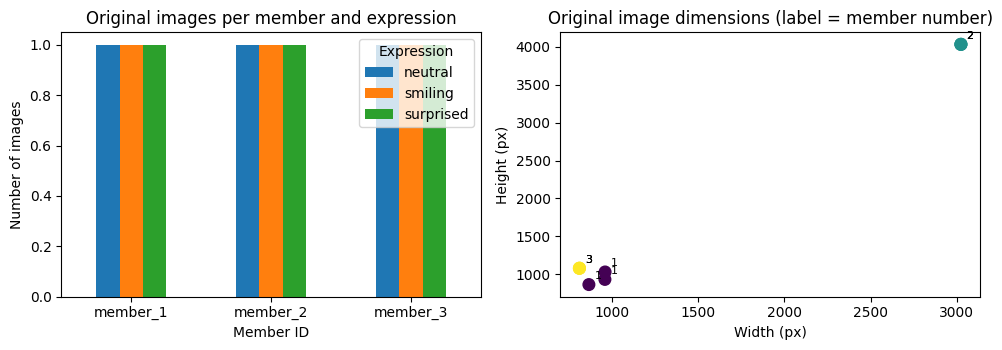

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
inspection.pivot_table(index="member_id", columns="expression", values="image_filename", aggfunc="count", fill_value=0).plot.bar(ax=ax[0], rot=0)
ax[0].set(title="Original images per member and expression", xlabel="Member ID", ylabel="Number of images"); ax[0].legend(title="Expression")
ax[1].scatter(inspection["width"], inspection["height"], c=inspection["member_id"].astype("category").cat.codes, s=70)
for r in inspection.itertuples(): ax[1].annotate(r.member_id[-1], (r.width, r.height), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[1].set(title="Original image dimensions (label = member number)", xlabel="Width (px)", ylabel="Height (px)")
plt.tight_layout(); savefig("02_dataset_distribution.png"); plt.show()

**What the dataset inspection shows**

The inspection found all **9 expected images**: each member has one neutral, one smiling and one surprised image. There were **no unreadable files, no duplicate files and no missing member/expression pairs**.

All images use RGB colour with three channels. Six files were identified as JPEG and three as MPO, but all nine were readable by the image-loading process. The image dimensions vary considerably, from **810 × 865** to **3024 × 4032** pixels.

The first chart confirms that the dataset is balanced across members and expressions. The resolution plot shows that the original images were not captured at one standard size. This makes consistent resizing and face alignment important before feature extraction.

## 5. Image visualisation

The nine original images are displayed together, arranged by member and facial expression. This gives a visual check of the dataset before face detection and preprocessing.

The images are loaded in RGB format so that their colours display correctly. Viewing the images at this stage also helps confirm that the expression labels match the visible photographs and that the faces are suitable for the next processing steps.

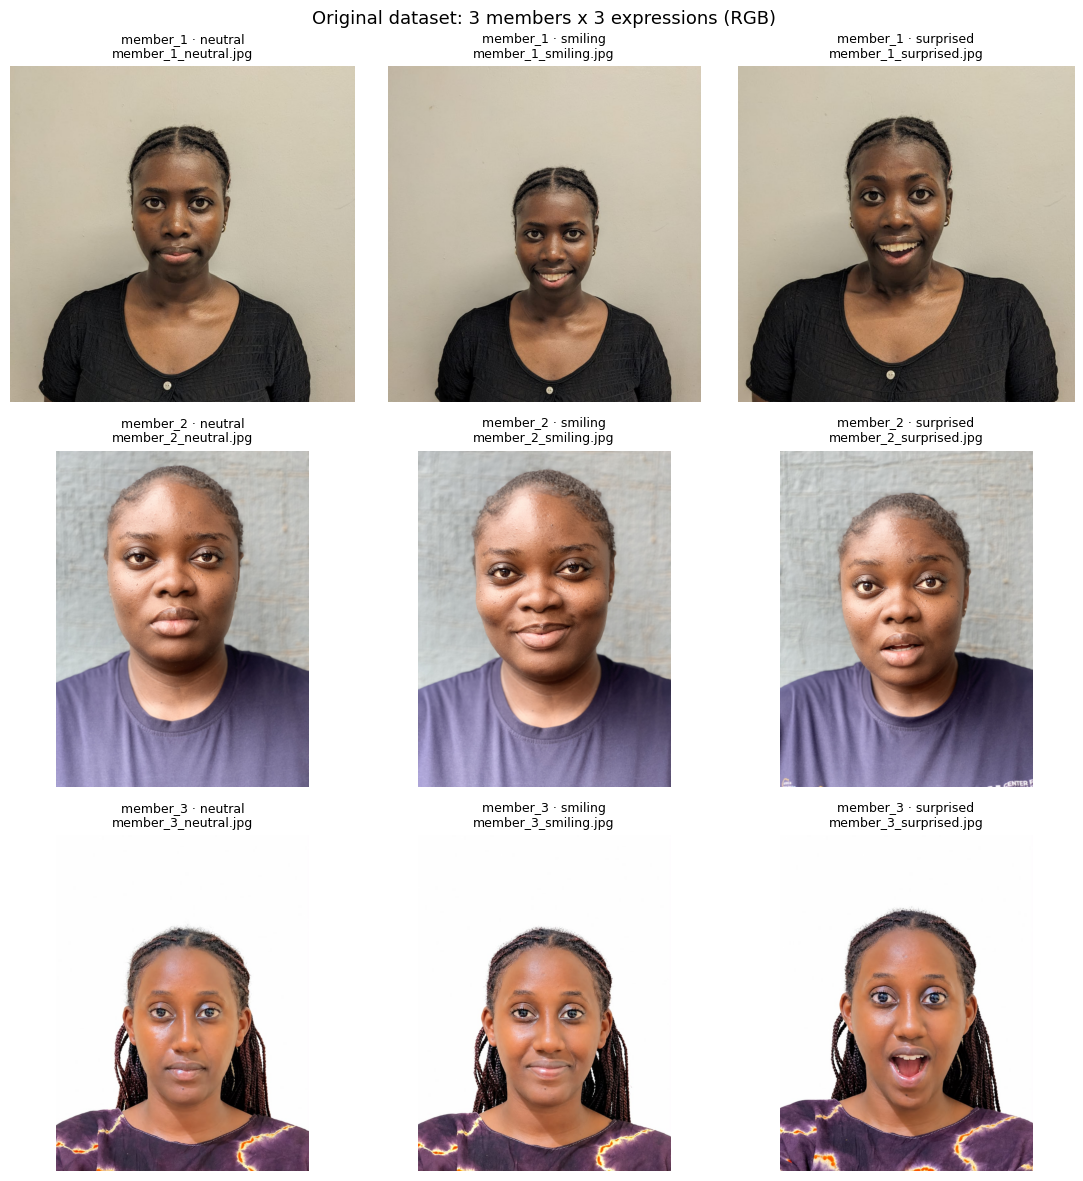

In [36]:
fig, axes = plt.subplots(3, 3, figsize=(11, 12))
for ax, m, e in [(axes[i][j], MEMBERS[i], EXPRESSIONS[j]) for i in range(3) for j in range(3)]:
    row = inspection[(inspection.member_id == m) & (inspection.expression == e)]
    ax.axis("off")
    if row.empty:
        ax.set_title(f"{m} / {e}\nMISSING", color="red"); continue
    r = row.iloc[0]
    ax.imshow(load_image_rgb(r.path, max_side=700))
    ax.set_title(f"{r.member_id} · {r.expression}\n{r.image_filename}", fontsize=9)
fig.suptitle("Original dataset: 3 members x 3 expressions (RGB)", fontsize=13)
plt.tight_layout(); savefig("01_original_images.png"); plt.show()

**Visual observations**

The grid displays all three expressions for each of the three members. The photographs show visible changes in facial expression, particularly around the mouth, eyes and eyebrows. The images also differ in their original dimensions, framing and capture conditions.

These differences are relevant to facial verification because the model needs to recognise the same person despite changes that do not represent a change in identity. The preprocessing stage addresses some of these differences by detecting, aligning and resizing the face regions.

## 6. Image preprocessing

The preprocessing pipeline prepares the original photographs for feature extraction. Each image follows the same sequence:

| Step | Purpose |
|---|---|
| EXIF orientation correction | Displays the image in its intended orientation. |
| RGB conversion | Ensures a consistent three-channel colour format. |
| Image-size limit | Resizes large images so that the longest side does not exceed 1024 pixels. |
| Face detection | Locates the face in the image using RetinaFace, with the configured fallback available. |
| Face alignment | Uses facial landmarks to align the detected face. |
| Face cropping and resizing | Produces a consistent 160 × 160 face image. |

Using the same process for every image reduces differences caused by image dimensions and face positioning. The pretrained model handles its required input normalisation during embedding extraction.

In [37]:
cfg = {**fx.DEFAULT_CONFIG, **json.loads((MODEL_DIR / "face_config.json").read_text(encoding="utf-8"))}

In [38]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

try:
    import tensorflow as tf
    print("TensorFlow version:", tf.__version__)
except Exception as e:
    print("TensorFlow ERROR:", repr(e))

try:
    import deepface
    print("DeepFace:", deepface.__file__)
except Exception as e:
    print("DeepFace ERROR:", repr(e))

try:
    import tf_keras
    print("TF-Keras: working")
except Exception as e:
    print("TF-Keras ERROR:", repr(e))

Python executable: /usr/bin/python3
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
TensorFlow version: 2.21.0
DeepFace: /usr/local/lib/python3.13/dist-packages/deepface/__init__.py
TF-Keras: working


In [39]:
# Make sure configuration exists
if "cfg" not in globals():
    cfg = {
        **fx.DEFAULT_CONFIG,
        **json.loads(
            (MODEL_DIR / "face_config.json").read_text(encoding="utf-8")
        )
    }

orig_paths = inspection.loc[
    inspection.readable, "path"
].tolist()

chosen, det_log = fx.select_detector(
    orig_paths,
    base_cfg=cfg,
    max_side=cfg["max_image_side"]
)

display(det_log)

if chosen is None:
    raise RuntimeError(
        "No face detector worked on all originals. "
        "Check the detector error log."
    )

cfg["detector_backend"] = chosen

print(
    "Selected detector:", chosen,
    "| model:", cfg["model_name"],
    "| threshold:", cfg["threshold"]
)

,detector,detected,total,last_error
0,retinaface,9,9,


Selected detector: retinaface | model: Facenet512 | threshold: 0.7


In [12]:
orig_paths = inspection.loc[inspection.readable, "path"].tolist()
chosen, det_log = fx.select_detector(orig_paths, base_cfg=cfg, max_side=cfg["max_image_side"])
display(det_log)
if chosen is None:
    raise RuntimeError("No face detector worked on all originals. Look at 'last_error' in the table above: "
                       "'ModelUnavailable' means DeepFace/TensorFlow is not importable in this kernel (see the preflight message in Section 2); "
                       "errors mentioning download/connection mean the model weights could not be downloaded (internet needed once).")
cfg["detector_backend"] = chosen
print("Selected detector:", chosen, "| model:", cfg["model_name"], "| threshold (cosine similarity):", cfg["threshold"])

,detector,detected,total,last_error
0,retinaface,9,9,


Selected detector: retinaface | model: Facenet512 | threshold (cosine similarity): 0.7


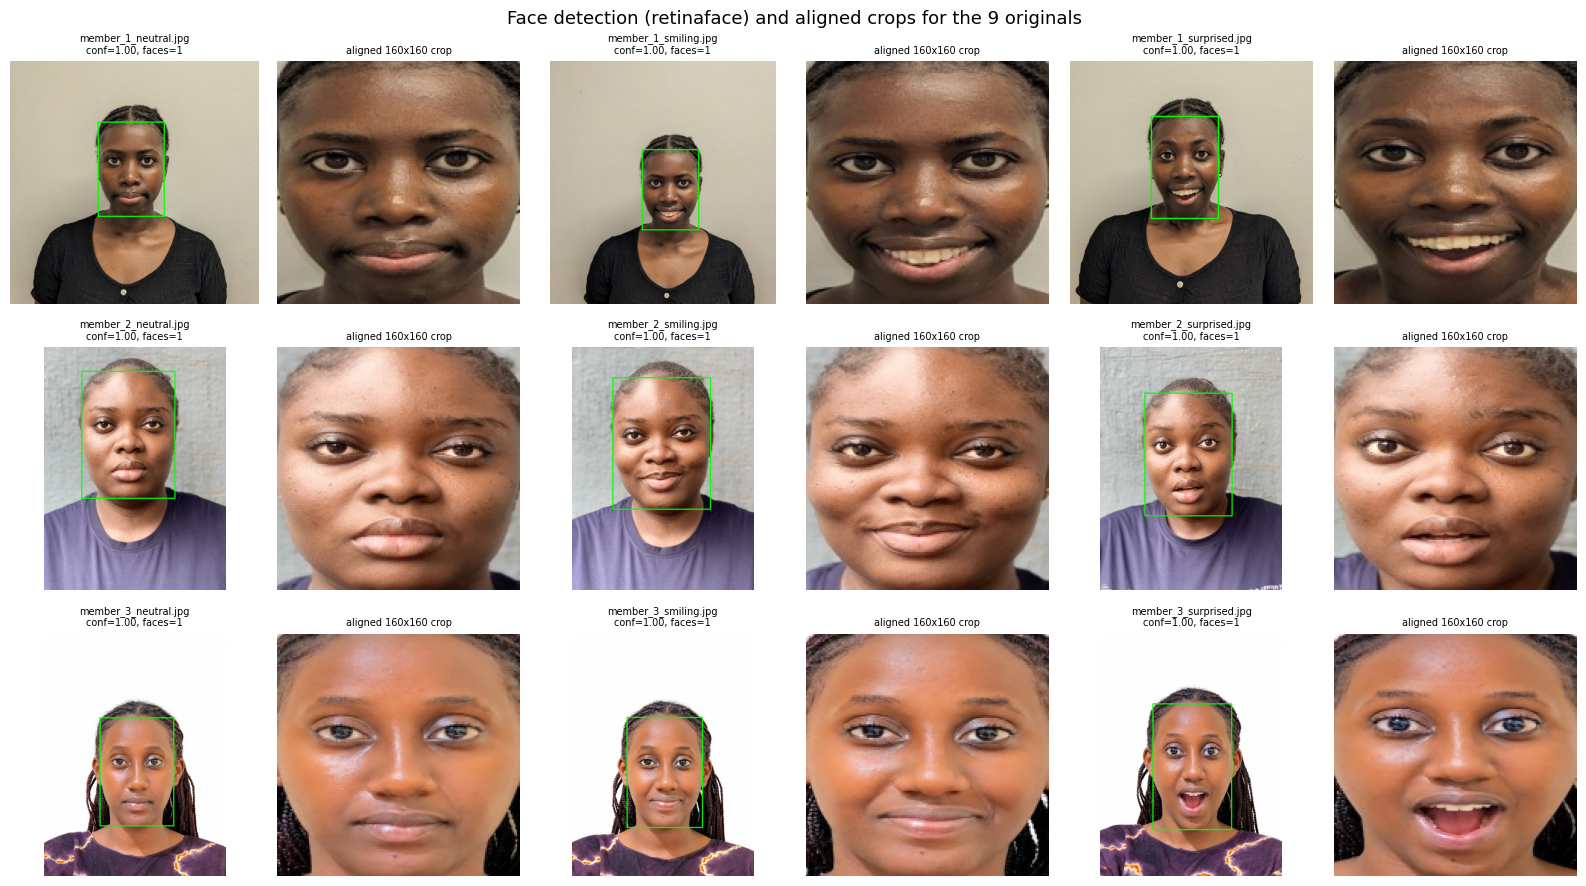

,image,n_faces,confidence,x,y,w,h,left_eye,right_eye,nose,mouth_left,mouth_right
0,member_1_neutral.jpg,1,1.0,339,234,254,362,"(523, 387)","(402, 384)","(459, 461)","(509, 517)","(414, 516)"
1,member_1_smiling.jpg,1,1.0,388,373,238,338,"(560, 515)","(449, 512)","(501, 584)","(552, 625)","(454, 624)"
2,member_1_surprised.jpg,1,1.0,289,197,239,363,"(466, 334)","(346, 336)","(406, 406)","(466, 458)","(355, 461)"
3,member_2_neutral.jpg,1,1.0,159,102,393,535,"(447, 318)","(261, 325)","(356, 422)","(431, 512)","(286, 518)"
4,member_2_smiling.jpg,1,1.0,172,129,412,554,"(462, 350)","(268, 365)","(363, 467)","(466, 536)","(290, 547)"
5,member_2_surprised.jpg,1,1.0,189,194,368,517,"(447, 394)","(271, 409)","(357, 501)","(434, 592)","(306, 603)"
6,member_3_neutral.jpg,1,1.0,236,357,311,455,"(468, 546)","(322, 545)","(393, 642)","(444, 714)","(337, 711)"
7,member_3_smiling.jpg,1,1.0,232,355,318,464,"(471, 542)","(321, 544)","(398, 645)","(457, 705)","(330, 707)"
8,member_3_surprised.jpg,1,1.0,223,298,332,530,"(473, 494)","(314, 493)","(393, 596)","(455, 688)","(326, 686)"


In [40]:
rows = []
fig, axes = plt.subplots(3, 6, figsize=(16, 9))
for k, r in enumerate(inspection[inspection.readable].itertuples()):
    rgb = load_image_rgb(r.path, cfg["max_image_side"])
    res = fx.get_embedding(rgb, cfg); fa = res["facial_area"]
    boxed = rgb.copy(); cv2.rectangle(boxed, (fa["x"], fa["y"]), (fa["x"] + fa["w"], fa["y"] + fa["h"]), (0, 255, 0), max(2, rgb.shape[1] // 200))
    crop_path = CROP_DIR / r.member_id / f"{Path(r.image_filename).stem}_face160.jpg"
    fx.save_aligned_crop(rgb, crop_path, cfg)
    i, j = divmod(k, 3)
    axes[i][2 * j].imshow(boxed);                  axes[i][2 * j].set_title(f"{r.image_filename}\nconf={res['face_confidence']:.2f}, faces={res['n_faces']}", fontsize=7)
    axes[i][2 * j + 1].imshow(load_image_rgb(crop_path)); axes[i][2 * j + 1].set_title("aligned 160x160 crop", fontsize=7)
    rows.append(dict(image=r.image_filename, n_faces=res["n_faces"], confidence=res["face_confidence"], **fa))
for a in axes.flat: a.axis("off")
fig.suptitle(f"Face detection ({cfg['detector_backend']}) and aligned crops for the 9 originals", fontsize=13)
plt.tight_layout(); savefig("03_face_detection_and_crops.png"); plt.show()
display(pd.DataFrame(rows))

**Face-detection result**

RetinaFace detected a face in **all 9 original images**. The detection log reports 9 successful detections out of 9, and the displayed table records one face per image with a confidence score of 1.0.

The green detection boxes and the aligned crops provide a visual check that the intended face region was located. No image in this dataset required a correction or removal at this stage. The detected and aligned face crops are therefore passed to feature extraction.

## 7. Image augmentation

Four augmented versions are created from every original image. This produces additional variations in appearance while retaining the identity of the person in the source photograph.

| Augmentation | Setting | Purpose |
|---|---|---|
| Rotation | +8° | Introduces a small change in image tilt. |
| Horizontal flip | Mirror image | Adds a mirrored version of the face. |
| Grayscale | Luminance conversion, retained as 3 channels | Reduces reliance on colour information. |
| Brightness | 1.20 gain | Introduces a brighter lighting condition. |

The original images remain unchanged. Augmented images are saved separately with filenames that identify the member, expression and augmentation type.

Augmentation increases the number of processed image examples, but it does not create new people or independent identity samples. For that reason, each augmented image remains linked to its original image during evaluation.

In [41]:
aug_manifest = generate_augmentations(inspection, AUG_DIR, max_side=cfg["max_image_side"])
aug_manifest.drop(columns=["output_path", "source_max_side"]).to_csv(PROC_DIR / "augmentation_manifest.csv", index=False)
n_orig = int(inspection.readable.sum())
print(f"Originals: {n_orig} | augmentations per original: {len(AUGMENTATIONS)} | augmented files written: {len(aug_manifest)} (minimum required: {2 * n_orig})")
display(aug_manifest[["member_id", "original_filename", "augmentation_type", "output_filename"]])
display(aug_manifest.groupby(["member_id", "augmentation_type"]).size().unstack())

Originals: 9 | augmentations per original: 4 | augmented files written: 36 (minimum required: 18)


,member_id,original_filename,augmentation_type,output_filename
0,member_1,member_1_neutral.jpg,rotation,member_1_neutral_rotation.jpg
1,member_1,member_1_neutral.jpg,flip,member_1_neutral_flip.jpg
2,member_1,member_1_neutral.jpg,grayscale,member_1_neutral_grayscale.jpg
3,member_1,member_1_neutral.jpg,brightness,member_1_neutral_brightness.jpg
4,member_1,member_1_smiling.jpg,rotation,member_1_smiling_rotation.jpg
5,member_1,member_1_smiling.jpg,flip,member_1_smiling_flip.jpg
6,member_1,member_1_smiling.jpg,grayscale,member_1_smiling_grayscale.jpg
7,member_1,member_1_smiling.jpg,brightness,member_1_smiling_brightness.jpg
8,member_1,member_1_surprised.jpg,rotation,member_1_surprised_rotation.jpg
9,member_1,member_1_surprised.jpg,flip,member_1_surprised_flip.jpg


augmentation_type,brightness,flip,grayscale,rotation
member_id,,,,
member_1,3,3,3,3
member_2,3,3,3,3
member_3,3,3,3,3


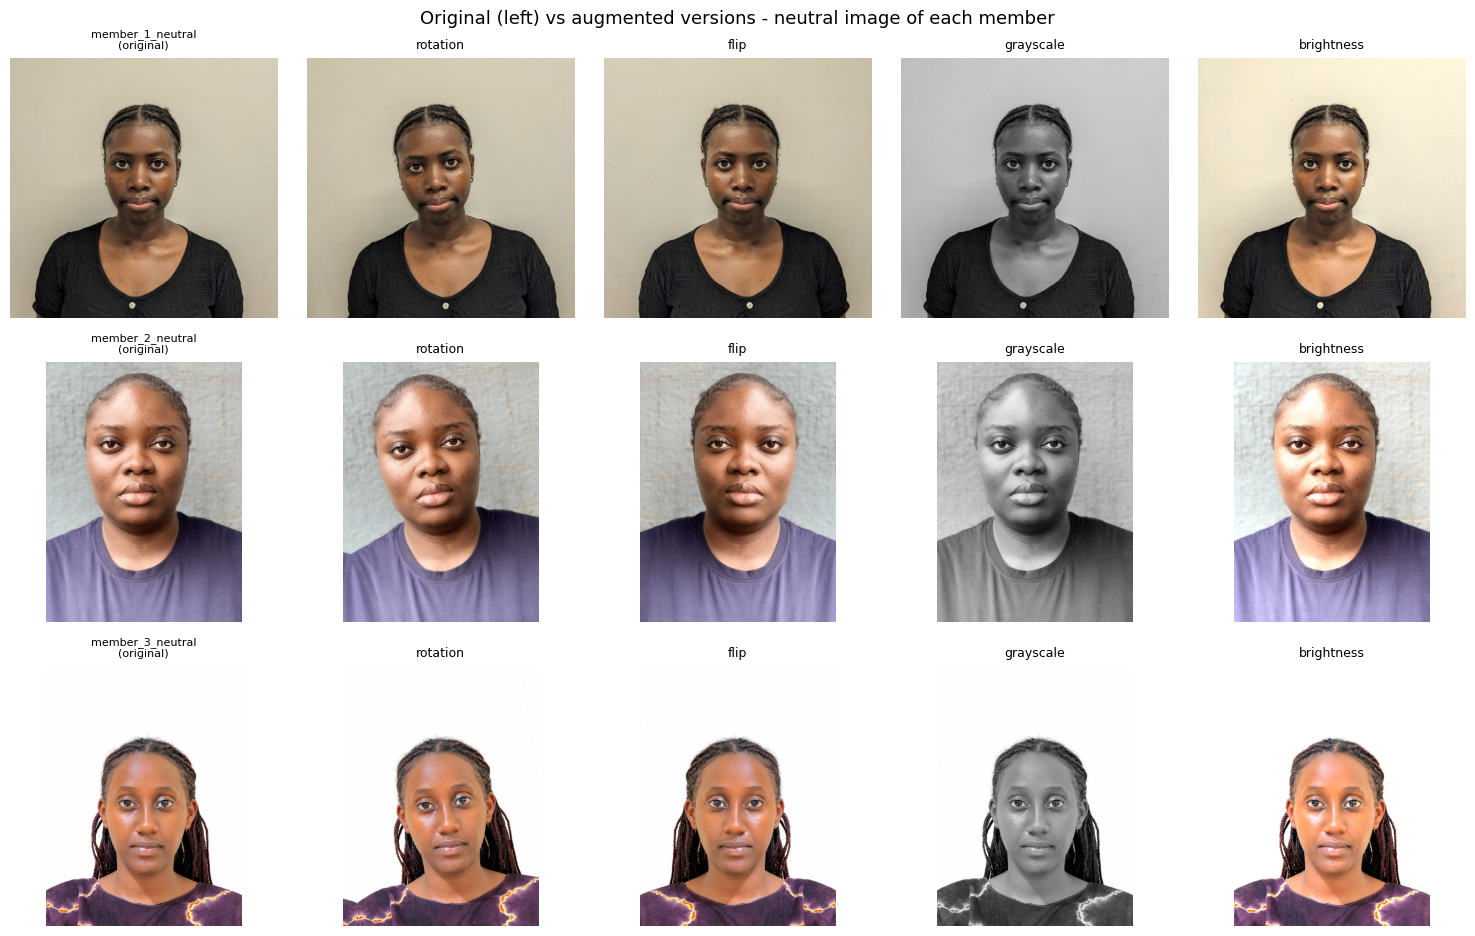

In [42]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9.5))
for i, m in enumerate(MEMBERS):
    src = inspection[(inspection.member_id == m) & (inspection.expression == "neutral")]
    if src.empty: continue
    stem = Path(src.iloc[0].image_filename).stem
    axes[i][0].imshow(load_image_rgb(src.iloc[0].path, 600)); axes[i][0].set_title(f"{stem}\n(original)", fontsize=8)
    for j, k in enumerate(AUGMENTATIONS, start=1):
        axes[i][j].imshow(load_image_rgb(AUG_DIR / m / f"{stem}_{k}.jpg", 600)); axes[i][j].set_title(k, fontsize=9)
for a in axes.flat: a.axis("off")
fig.suptitle("Original (left) vs augmented versions - neutral image of each member", fontsize=13)
plt.tight_layout(); savefig("04_augmentation_examples.png"); plt.show()

**Augmentation result**

The process started with **9 original images** and generated **4 augmented versions per original**, giving **36 augmented images**. This is above the minimum requirement of 18 augmented images.

The output table records the source image and the augmentation applied to each copy. The count plot confirms that each member has the same number of rotation, flip, grayscale and brightness versions: three of each augmentation type per member.

The visual examples show how these transformations change the appearance of the photographs. They provide useful variation for the feature-building process, but they are still derived from the same nine original photographs and are not independent data.

## 8. Facial feature extraction

A facial embedding is a numerical representation of a detected face. In this notebook, the pretrained **FaceNet512** model converts each aligned face image into a vector containing **512 numerical features**.

The purpose of the embedding is to represent facial characteristics in a form that can be compared mathematically. Images of the same person are expected to produce more similar embeddings than images of different people, even when the expression or image appearance changes.

The pretrained model is used to extract the features; it is not trained from scratch on the nine photographs in this dataset. Both the original and augmented images are processed. Any failed extraction is recorded separately rather than being replaced with fabricated feature values.

In [43]:
features, failures = fx.build_feature_table(inspection, aug_manifest, cfg)
emb_cols = fx.embedding_columns(features)
features.to_csv(PROC_DIR / "image_features.csv", index=False)
failures.to_csv(EVAL_DIR / "feature_extraction_failures.csv", index=False)

print("Feature table shape:", features.shape, f"-> {len(features)} images x ({features.shape[1] - len(emb_cols)} metadata cols + {len(emb_cols)} embedding cols)")
print("Failed extractions   :", len(failures));
if len(failures): display(failures)
print("Missing values       :", int(features[emb_cols].isna().sum().sum()))
print("Non-finite values    :", int((~np.isfinite(features[emb_cols].to_numpy())).sum()))
print("Originals / augmented:", int(features.is_original.sum()), "/", int((~features.is_original).sum()))
display(features.groupby(["member_id", "is_original"]).size().unstack(fill_value=0).rename(columns={True: "original", False: "augmented"}))
display(features.iloc[:5, :16])

Feature table shape: (45, 526) -> 45 images x (14 metadata cols + 512 embedding cols)
Failed extractions   : 0
Missing values       : 0
Non-finite values    : 0
Originals / augmented: 9 / 36


is_original,augmented,original
member_id,,
member_1,12,3
member_2,12,3
member_3,12,3


,member_id,image_filename,expression,augmentation_type,original_filename,is_original,detector_backend,model_name,n_faces_detected,face_confidence,face_x,face_y,face_w,face_h,embedding_0,embedding_1
0,member_1,member_1_neutral.jpg,neutral,none,member_1_neutral.jpg,True,retinaface,Facenet512,1,1.0,339,234,254,362,-0.383789,-0.969159
1,member_1,member_1_smiling.jpg,smiling,none,member_1_smiling.jpg,True,retinaface,Facenet512,1,1.0,388,373,238,338,-0.035355,-1.265700
2,member_1,member_1_surprised.jpg,surprised,none,member_1_surprised.jpg,True,retinaface,Facenet512,1,1.0,289,197,239,363,-0.406633,-0.907888
3,member_2,member_2_neutral.jpg,neutral,none,member_2_neutral.jpg,True,retinaface,Facenet512,1,1.0,159,102,393,535,-1.999111,-1.213386
4,member_2,member_2_smiling.jpg,smiling,none,member_2_smiling.jpg,True,retinaface,Facenet512,1,1.0,172,129,412,554,-2.088763,-1.385613


In [44]:
# processed-image manifest (aligned 160x160 crops for ALL originals + augmented images)
man = []
for r in features.itertuples():
    src = (RAW_DIR / r.member_id / r.image_filename) if r.is_original else (AUG_DIR / r.member_id / r.image_filename)
    crop = CROP_DIR / r.member_id / f"{Path(r.image_filename).stem}_face160.jpg"
    if not crop.exists():
        fx.save_aligned_crop(load_image_rgb(src, cfg["max_image_side"]), crop, cfg)
    man.append(dict(member_id=r.member_id, image_filename=r.image_filename, expression=r.expression, augmentation_type=r.augmentation_type,
                    is_original=r.is_original, source_path=str(src), processed_crop_path=str(crop), crop_size="160x160",
                    detector_backend=cfg["detector_backend"], face_detected=True))
for r in failures.itertuples():
    man.append(dict(member_id=r.member_id, image_filename=r.image_filename, expression=r.expression, augmentation_type=r.augmentation_type,
                    is_original=r.is_original, source_path=r.path, processed_crop_path=None, crop_size=None,
                    detector_backend=cfg["detector_backend"], face_detected=False))
manifest = pd.DataFrame(man); manifest.to_csv(PROC_DIR / "processed_image_manifest.csv", index=False)
print("processed_image_manifest.csv:", manifest.shape, "| faces detected:", int(manifest.face_detected.sum()), "of", len(manifest))

processed_image_manifest.csv: (45, 10) | faces detected: 45 of 45


**Feature extraction result**

The feature table contains **45 rows and 526 columns**: 14 metadata columns and 512 embedding values for each image. These 45 rows represent the 9 original images and 36 augmented images.

The extraction completed with **0 failed extractions, 0 missing values and 0 non-finite values**. Each member contributes 3 original images and 12 augmented images, giving 15 processed images per member.

The metadata columns retain information such as member ID, expression, source filename, augmentation type, detector backend and face-detection details. The 512 embedding columns contain the numerical features used by the verification model. The processed-image manifest also confirms that faces were detected in all 45 processed images.

## 9. Facial verification model

The verification model uses the FaceNet512 embeddings to compare a submitted face image with the enrolled members.

**How the model works**

1. **Enrolment:** The embeddings belonging to each member are combined into one representative template. The vectors are L2-normalised before averaging, and the resulting template is normalised again.
2. **Comparison:** A face submitted for verification is detected and converted into an embedding. Cosine similarity measures how closely it matches each enrolled template.
3. **Decision:** The model identifies the highest-scoring template. It accepts the match only when the best cosine similarity is at least **0.70**. Otherwise, the image is rejected and no member ID is returned.

The threshold is set at 0.70, equivalent to a cosine distance of 0.30 for FaceNet512. This is the documented DeepFace operating threshold for this model and distance metric. It is fixed before evaluation rather than adjusted to produce a better result on this small dataset.

The saved templates used by the application are built from all 45 enrolled-member image records (the nine originals and their 36 augmented copies); no unknown-person image is used. The evaluation in the next section uses a separate leave-one-expression-out protocol so that each genuine probe is held out from the template used for that trial.

In [45]:
try:
    from deepface.modules import verification as _v
    print("DeepFace documented cosine DISTANCE threshold for", cfg["model_name"], "=", _v.find_threshold(cfg["model_name"], "cosine"),
          "-> similarity", round(1 - _v.find_threshold(cfg["model_name"], "cosine"), 2))
except Exception as exc:
    print("Could not cross-check threshold automatically:", type(exc).__name__)

member_ids, templates = ev.build_templates(features, emb_cols, MEMBERS)
print("Templates:", templates.shape, "| unit norms:", np.linalg.norm(templates, axis=1).round(4))

def _ver(pkg):
    try: return metadata.version(pkg)
    except Exception: return "n/a"
meta = dict(model_name=cfg["model_name"], detector_backend=cfg["detector_backend"], embedding_dim=len(emb_cols),
            n_original_images=int(features.is_original.sum()), n_augmented_images=int((~features.is_original).sum()),
            enrolled_member_ids=member_ids, created_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
            library_versions={p: _ver(p) for p in ["deepface", "tensorflow", "tf-keras", "opencv-python-headless", "numpy", "pandas", "scikit-learn", "pillow"]},
            templates_sha256=hashlib.sha256(templates.astype("float32").tobytes()).hexdigest(),
            status="academic prototype - not for real financial authentication")
fm.save_model_resources(member_ids, templates, {k: cfg[k] for k in ["model_name", "detector_backend", "similarity_metric", "threshold", "max_image_side", "align", "embedding_dim", "template_method"]}, meta)
(EVAL_DIR / "environment.txt").write_text(encoding="utf-8", data="\n".join(f"{k}=={v}" for k, v in meta["library_versions"].items()) + f"\npython=={platform.python_version()}\n")
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir() if p.name != ".gitkeep"))

DeepFace documented cosine DISTANCE threshold for Facenet512 = 0.3 -> similarity 0.7
Templates: (3, 512) | unit norms: [1. 1. 1.]
Saved: ['face_config.json', 'face_templates.npy', 'model_metadata.json']


### Testing the saved verification function

The `verify_face(image_path)` function loads the saved model files from the project directory. The checks below confirm that the saved model can identify the three enrolled members and handle a missing image path.

The three enrolled photographs are used here as a **smoke test**. They were also used to build the saved templates, so their scores are not independent evidence of model accuracy. The held-out evaluation in Section 10 provides a more appropriate check of verification performance.

The unknown-person images are tested separately in **Section 11**. That section loads the photographs from the per-person folders inside `data/test_unknown/person_N/`, processes them using the same pipeline and compares them against the final saved templates. The smoke test here does not replace that separate test.

In [46]:
import importlib; importlib.reload(fm)
from src.face_model import verify_face
for m in MEMBERS:
    print(m, "->", verify_face(RAW_DIR / m / f"{m}_neutral.jpg"))
print("missing file ->", verify_face("no_such_image.jpg"))
unknown_imgs = [p for p in Path("data/test_unknown").glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
for p in unknown_imgs:
    print("unknown test image", p.name, "->", verify_face(p))
if not unknown_imgs:
    print("\n(No consented unknown-person image in data/test_unknown/: that real-world test is PENDING.)")

member_1 -> {'verified': True, 'user_id': 'member_1', 'score': 0.9825, 'message': 'Face verified successfully', 'status': 'verified', 'best_match': 'member_1', 'threshold': 0.7, 'num_faces': 1}
member_2 -> {'verified': True, 'user_id': 'member_2', 'score': 0.9716, 'message': 'Face verified successfully', 'status': 'verified', 'best_match': 'member_2', 'threshold': 0.7, 'num_faces': 1}
member_3 -> {'verified': True, 'user_id': 'member_3', 'score': 0.9683, 'message': 'Face verified successfully', 'status': 'verified', 'best_match': 'member_3', 'threshold': 0.7, 'num_faces': 1}
missing file -> {'verified': False, 'user_id': None, 'score': None, 'message': 'Image file not found: no_such_image.jpg', 'status': 'file_not_found', 'best_match': None, 'threshold': 0.7, 'num_faces': None}

(No consented unknown-person image in data/test_unknown/: that real-world test is PENDING.)


## 10. Model evaluation

The evaluation checks how the model performs when it compares genuine members, enrolled members who are not the correct person, and people who were not enrolled in a particular evaluation run.

To reduce data leakage, an original image and all its augmented copies remain together. Augmented copies are not treated as independent test photographs.

### Evaluation protocols

- **Leave-one-expression-out:** For each expression, the model builds templates using the other two expressions and their augmented copies. The held-out original image is then used as the probe. This produces 9 genuine trials and 18 enrolled-impostor comparisons.
- **Leave-one-member-out:** One member is left out of enrolment, and that member's three original images are tested against the other two members' templates. These 9 trials check whether a person who is not enrolled in that run is rejected.
- **Augmented-probe check:** Augmented versions of the held-out images are also tested separately. These results indicate robustness to the applied transformations, but they are not independent samples.

### Evaluation measures

- **False Rejection Rate (FRR):** The proportion of genuine attempts that are incorrectly rejected.
- **False Acceptance Rate (FAR):** The proportion of impostor or unknown-person attempts that are incorrectly accepted.
- **Accuracy, precision, recall and F1-score:** Measures of the final four-class decision across the three member identities and the unknown class.

The dataset is very small: 9 genuine trials, 18 enrolled-impostor comparisons and 9 unknown-person trials. The confidence intervals are included to show the uncertainty associated with these small sample sizes. Results from this evaluation are exploratory and are not enough to establish real-world biometric security.

**Note on the word "unknown" in this section.** The unknown-person trials above were created by temporarily treating one *enrolled* member as not enrolled. They are real photographs of real people, but only two identities are enrolled in each of those runs. **Section 11** extends this evaluation with photographs of three people who were never enrolled, tested against the final saved templates. The results in this section are kept unchanged as the **initial evaluation**.

In [47]:
THRESHOLD = float(cfg["threshold"])
R = ev.run_full_evaluation(features, THRESHOLD)
R["loeo"].to_csv(EVAL_DIR / "trials_leave_one_expression_out.csv", index=False)
R["unknown"].to_csv(EVAL_DIR / "trials_unknown_person.csv", index=False)
R["augmented"].to_csv(EVAL_DIR / "trials_augmented_probe_robustness.csv", index=False)
R["sweep"].to_csv(EVAL_DIR / "threshold_sweep_exploratory.csv", index=False)
(EVAL_DIR / "evaluation_metrics.json").write_text(json.dumps({k: R[k] for k in ["closed_set", "verification", "open_set", "augmented_robustness"]}, indent=2, default=str), encoding="utf-8")

v, o = R["verification"], R["open_set"]
f = lambda x: "n/a" if x is None else f"{x:.3f}"
ci = lambda t: "n/a" if t is None or t[0] is None else f"[{t[0]:.2f}, {t[1]:.2f}]"
print(f"Threshold (cosine similarity): {THRESHOLD}")
print(f"Closed-set top-1 identification accuracy (nearest template, 3 classes): {f(R['closed_set']['top1_accuracy'])}  (n={R['closed_set']['n']})")
print(f"Genuine trials  : {v['n_genuine']:>2} -> accepted {v['genuine_accept']}, FRR = {f(v.get('FRR'))}  95%CI {ci(v.get('FRR_ci95'))}")
print(f"Enrolled impostor: {v['n_impostor']:>2} -> rejected {v['impostor_reject']}, FAR = {f(v.get('FAR_enrolled_impostor'))}  95%CI {ci(v.get('FAR_enrolled_impostor_ci95'))}")
print(f"Unknown person  : {v['n_unknown']:>2} -> rejected {v['unknown_reject']}, FAR = {f(v.get('FAR_unknown'))}  95%CI {ci(v.get('FAR_unknown_ci95'))}")
print(f"Lowest genuine score {f(v['min_genuine_score'])} | highest impostor score {f(v['max_impostor_score'])} | highest unknown best-score {f(v['max_unknown_best_score'])} | separable: {v['scores_separable']}")
print(f"\n4-class open-set decision (n={o['n_samples']}): accuracy={f(o['accuracy'])}, macro precision={f(o['macro_precision'])}, macro recall={f(o['macro_recall'])}, macro F1={f(o['macro_f1'])}")
display(pd.DataFrame(o["per_class"]).round(3))
print("Augmented-probe robustness (not independent):", R["augmented_robustness"])

Threshold (cosine similarity): 0.7
Closed-set top-1 identification accuracy (nearest template, 3 classes): 1.000  (n=9)
Genuine trials  :  9 -> accepted 9, FRR = 0.000  95%CI [0.00, 0.30]
Enrolled impostor: 18 -> rejected 18, FAR = 0.000  95%CI [0.00, 0.18]
Unknown person  :  9 -> rejected 9, FAR = 0.000  95%CI [0.00, 0.30]
Lowest genuine score 0.906 | highest impostor score 0.532 | highest unknown best-score 0.549 | separable: True

4-class open-set decision (n=18): accuracy=1.000, macro precision=1.000, macro recall=1.000, macro F1=1.000


,label,precision,recall,f1,support
0,member_1,1.0,1.0,1.0,3
1,member_2,1.0,1.0,1.0,3
2,member_3,1.0,1.0,1.0,3
3,unknown,1.0,1.0,1.0,9


Augmented-probe robustness (not independent): {'n': 36, 'accepted_as_correct_member': 1.0}


### Interpreting the evaluation results

At the selected threshold of **0.70**, the lowest genuine similarity score is **0.906**. The highest enrolled-impostor score is **0.532**, while the highest leave-one-member-out unknown-probe score is **0.549**. In these evaluation trials, the genuine scores are above the threshold and the impostor/unknown-probe scores are below it.

The model accepted all 9 genuine trials, rejected all 18 enrolled-impostor comparisons and rejected all 9 leave-one-member-out unknown probes. The resulting FRR is **0.000**, and the FAR is **0.000** for the two impostor groups in this evaluation.

These results are encouraging, but they need to be read alongside the confidence intervals: **0.00–0.30 for FRR, 0.00–0.18 for enrolled-impostor FAR and 0.00–0.30 for the leave-one-member-out unknown-probe FAR**. The evaluation includes only three people, with three original photographs per person, captured in one session.

There are also limitations in the data. Differences in cameras, backgrounds and capture conditions may be associated with the member identities. The model has no liveness or spoof-detection component, and the dataset does not support a demographic fairness assessment.

A stronger evaluation requires photographs from multiple sessions, different lighting and angles, genuine images held out from enrolment, and a larger group of consented unknown participants. The current results show separation on this dataset; they do not prove that the system is ready for real-world authentication.

## 11. Unknown-Person Verification and Unauthorised Access Testing

### Purpose of this test

Section 10 evaluated the verification process using genuine member trials, enrolled-impostor comparisons and leave-one-member-out probes. In the leave-one-member-out protocol, one of the enrolled members is temporarily left out of the templates for that particular run. Those probes are useful for evaluation, but they are not photographs of people who have never been enrolled in the project.

This section adds a separate test using photographs of **three people who are not enrolled in the system**. Each person has three expressions: neutral, smiling and surprised. This gives **nine unknown-person test images**.

The aim is to check whether the saved verification system rejects people who are not registered. The enrolled templates created earlier remain the reference for this test. The unknown images are processed and compared against those templates, but they do not become part of the enrolled dataset.

### Why the unknown images are kept separate from the enrolled images

- They are stored in their own folder, `data/test_unknown/person_N/`, and not in `data/raw/images/`.
- They are **not augmented**, **not added to `image_features.csv`** and **not used to build or update the member templates**. The templates are only read during this section.
- If an unknown person's photograph influenced the templates, the test would no longer measure whether the system can reject someone who is not registered. This would introduce **data leakage** and make the result unreliable.
- The notebook checks that the saved templates and enrolled feature table remain unchanged after the test, and that unknown images have not entered the enrolled feature table.

### How the system decides whether a person is authorised

| Step | What happens |
|---|---|
| 1. Preprocessing | The same pipeline used for enrolled images is applied: EXIF orientation correction, RGB conversion, image-size handling, RetinaFace face detection, landmark alignment, face cropping and resizing to 160 × 160 pixels. |
| 2. Embedding extraction | FaceNet512 converts the aligned face into a 512-dimensional numerical vector. |
| 3. Comparison | Cosine similarity compares the unknown person's embedding with each of the three saved enrolled-member templates. A higher score means the embeddings are more similar. |
| 4. Closest identity | The template with the highest similarity is recorded as the closest enrolled identity. This is only a comparison result; it does not automatically grant access. |
| 5. Threshold | The highest similarity score is compared with the fixed threshold of **0.70**, the same threshold used in the earlier verification stages. It is not adjusted using the unknown-person images. |
| 6. Decision | The image is **ACCEPTED** if its highest similarity is 0.70 or above. It is **REJECTED** if the highest similarity is below 0.70. |

### Key terms

- **Correct rejection:** an unknown person is rejected because their highest similarity score is below the threshold. This is the expected result.
- **False acceptance:** an unknown person is accepted because their highest similarity score reaches or exceeds the threshold. This is an incorrect decision and a potential security failure.
- **Failed image:** the file cannot be read, no face is detected, or a valid embedding cannot be produced. A failed image is reported separately; it is not counted as a correct rejection.

### Folder structure used in this section

```text
data/test_unknown/person_1/
data/test_unknown/person_2/
data/test_unknown/person_3/
data/processed/unknown_file_mapping.csv
outputs/unknown_processed_images/
outputs/evaluation/unknown_person_*.csv
outputs/evaluation/unknown_person_*.json
outputs/evaluation/unknown_person_*.md
```

The per-person folders keep the unknown images organised by identity and expression. The processed crops and evaluation outputs are also saved separately from the enrolled-member files.

### 11.1 Loading and inspecting the unknown-person images

The cell below locates the unknown-person images in `data/test_unknown/`. The expected structure contains one folder for each unknown person, with neutral, smiling and surprised images inside each folder.

If the folder is empty, the images can be supplied through the ZIP option configured in the loading cell. The notebook maps the supplied filenames to the expected person and expression labels. It also reports missing files, unreadable images and files that are identical to an enrolled image.

Keeping this loading step separate from the enrolled dataset is important. The unknown images are test inputs only; they are not added to the original image collection, the augmentation process or the reference templates.

In [48]:
import importlib, hashlib
from IPython.display import Markdown
from src import unknown_testing as ut
importlib.reload(ut)
from src.image_preprocessing import sha256_of

UNKNOWN_DIR      = Path("data/test_unknown")               # person_N/person_N_<expression>.jpg  (never inside data/raw/images)
UNKNOWN_CROP_DIR = Path("outputs/unknown_processed_images")
UNKNOWN_ZIP_PATH = None     # optional: ZIP with 'Person N/<expression>' folders; only used when data/test_unknown is empty
UNKNOWN_CROP_DIR.mkdir(parents=True, exist_ok=True)
THRESHOLD = float(cfg["threshold"])

n_unknown_found = len([p for p in UNKNOWN_DIR.rglob("*") if p.is_file() and p.suffix.lower() in ut.IMAGE_EXTS])
print("Unknown-person images already in data/test_unknown:", n_unknown_found)
if n_unknown_found == 0:
    zip_path = UNKNOWN_ZIP_PATH
    if zip_path is None and IN_COLAB:
        from google.colab import files
        print("Upload the UNKNOWN-PERSONS ZIP (folders 'Person 1', 'Person 2', ...) ...")
        up = [n for n in files.upload() if n.lower().endswith(".zip")]
        zip_path = up[0] if up else None
    if zip_path is None:
        print("No unknown-person images supplied. Place them as data/test_unknown/person_N/person_N_<expression>.jpg "
              "or set UNKNOWN_ZIP_PATH, then run this cell again.")
    else:
        mapping = ut.ingest_unknown_zip(zip_path, UNKNOWN_DIR, PROC_DIR / "unknown_file_mapping.csv", enrolled_dir=RAW_DIR)
        display(mapping.drop(columns=[c for c in ["sha256"] if c in mapping.columns]))
elif (PROC_DIR / "unknown_file_mapping.csv").exists():
    print("Showing the saved file-name mapping (supplied upload name -> canonical name):")
    display(pd.read_csv(PROC_DIR / "unknown_file_mapping.csv").drop(columns=["sha256"], errors="ignore"))

Unknown-person images already in data/test_unknown: 9
Showing the saved file-name mapping (supplied upload name -> canonical name):


,zip_relative_path,original_extension,status,person_id,expression,canonical_path
0,images/Unauthorized-persons/Person 1/neutral.j...,.jepg.jpeg,ok,person_1,neutral,person_1/person_1_neutral.jpg
1,images/Unauthorized-persons/Person 1/smiling.j...,.jepg.jpeg,ok,person_1,smiling,person_1/person_1_smiling.jpg
2,images/Unauthorized-persons/Person 1/surprised...,.jepg.jpeg,ok,person_1,surprised,person_1/person_1_surprised.jpg
3,images/Unauthorized-persons/Person 2/neutral.jpeg,.jpeg,ok,person_2,neutral,person_2/person_2_neutral.jpg
4,images/Unauthorized-persons/Person 2/smiling.jpeg,.jpeg,ok,person_2,smiling,person_2/person_2_smiling.jpg
5,images/Unauthorized-persons/Person 2/suprised....,.jpeg,ok,person_2,surprised,person_2/person_2_surprised.jpg
6,images/Unauthorized-persons/Person 3/neutral.jpeg,.jpeg,ok,person_3,neutral,person_3/person_3_neutral.jpg
7,images/Unauthorized-persons/Person 3/smiling.jpeg,.jpeg,ok,person_3,smiling,person_3/person_3_smiling.jpg
8,images/Unauthorized-persons/Person 3/suprised....,.jpeg,ok,person_3,surprised,person_3/person_3_surprised.jpg


In [49]:
unk_inspection = ut.inspect_unknown_images(UNKNOWN_DIR, enrolled_dir=RAW_DIR)
if unk_inspection.empty:
    raise RuntimeError("No unknown-person images found in data/test_unknown/. See the previous cell for how to supply them.")
display(unk_inspection.drop(columns=["path", "sha256"]))
unk_inspection.drop(columns=["path"]).to_csv(EVAL_DIR / "unknown_dataset_inspection.csv", index=False)

missing_unknown = ut.missing_unknown_items(unk_inspection)
print(f"\nUnknown-person images found : {len(unk_inspection)}  (persons: {sorted(unk_inspection.person_id.dropna().unique())})")
print(f"Unreadable files            : {int((~unk_inspection.readable).sum())}")
print("Missing person/expression pairs:", missing_unknown if missing_unknown else "none")
print("Images per person:"); display(unk_inspection.groupby("person_id").size().rename("n_images").to_frame())

# ---- leakage guard 1: unknown images must be different files from enrolled images and live outside the enrolled folder ----
dups = unk_inspection[unk_inspection.identical_to_enrolled_image.notna()]
inside_raw = [p for p in unk_inspection.path if RAW_DIR.resolve() in Path(p).resolve().parents]
assert dups.empty, f"Unknown-person images identical to enrolled images (remove them): {dups.image_filename.tolist()}"
assert not inside_raw, f"Unknown-person images found inside the enrolled folder: {inside_raw}"
print("Leakage guard 1 passed: no unknown image is identical to an enrolled image, and none is stored in data/raw/images.")

# ---- baseline snapshot of everything that must NOT change during this test ----
verifier = fm.FaceVerifier.load()                         # reads templates saved in models/face/ (enrolled members only)
templates_saved, member_ids_saved = verifier.templates.copy(), list(verifier.member_ids)
_sha = lambda a: hashlib.sha256(np.asarray(a, dtype="float32").tobytes()).hexdigest()
snap_before = dict(
    templates_array_sha=_sha(templates_saved),
    templates_file_sha=sha256_of(MODEL_DIR / "face_templates.npy"),
    features_csv_sha=sha256_of(PROC_DIR / "image_features.csv") if (PROC_DIR / "image_features.csv").exists() else None)
meta_saved = json.loads((MODEL_DIR / "model_metadata.json").read_text(encoding="utf-8"))
print("Loaded templates for:", member_ids_saved, "| shape", templates_saved.shape,
      "| matches templates_sha256 in model_metadata.json:", snap_before["templates_array_sha"] == meta_saved["templates_sha256"])

# enrolled feature table and the initial evaluation (needed for the comparison later; recomputed from the saved CSV if the kernel was restarted)
if "features" not in globals():
    features = pd.read_csv(PROC_DIR / "image_features.csv"); emb_cols = fx.embedding_columns(features)
    print("(features loaded from data/processed/image_features.csv)")
if "R" not in globals():
    R = ev.run_full_evaluation(features, THRESHOLD)
    print("(initial evaluation recomputed from the enrolled features)")
n_features_before = len(features)
print("Enrolled feature rows (must stay unchanged):", n_features_before)

,person_id,expression,image_filename,file_size_kb,identical_to_enrolled_image,format,width,height,mode,exif_orientation,readable,error
0,person_1,neutral,person_1_neutral.jpg,86.6,None,JPEG,720,1280,RGB,1,True,
1,person_1,smiling,person_1_smiling.jpg,92.4,None,JPEG,720,1280,RGB,1,True,
2,person_1,surprised,person_1_surprised.jpg,90.2,None,JPEG,720,1280,RGB,1,True,
3,person_2,neutral,person_2_neutral.jpg,33.1,None,JPEG,780,726,RGB,1,True,
4,person_2,smiling,person_2_smiling.jpg,32.4,None,JPEG,780,726,RGB,1,True,
5,person_2,surprised,person_2_surprised.jpg,33.6,None,JPEG,780,722,RGB,1,True,
6,person_3,neutral,person_3_neutral.jpg,30.5,None,JPEG,777,758,RGB,1,True,
7,person_3,smiling,person_3_smiling.jpg,31.5,None,JPEG,780,730,RGB,1,True,
8,person_3,surprised,person_3_surprised.jpg,35.6,None,JPEG,780,853,RGB,1,True,



Unknown-person images found : 9  (persons: ['person_1', 'person_2', 'person_3'])
Unreadable files            : 0
Missing person/expression pairs: none
Images per person:


,n_images
person_id,
person_1,3
person_2,3
person_3,3


Leakage guard 1 passed: no unknown image is identical to an enrolled image, and none is stored in data/raw/images.
Loaded templates for: ['member_1', 'member_2', 'member_3'] | shape (3, 512) | matches templates_sha256 in model_metadata.json: True
Enrolled feature rows (must stay unchanged): 45


### 11.2 Visual inspection of the unknown-person images

The nine unknown-person images are displayed before processing, with the person and expression labels shown alongside each image. The images are loaded with their EXIF orientation applied and displayed in RGB format.

This visual check confirms that the expected files are available and that the neutral, smiling and surprised labels correspond to the photographs. It also provides an opportunity to notice obvious image-quality issues, such as a face being too small, partly covered or poorly framed, before interpreting the verification results.

The images remain separate from the enrolled-member images throughout this stage.

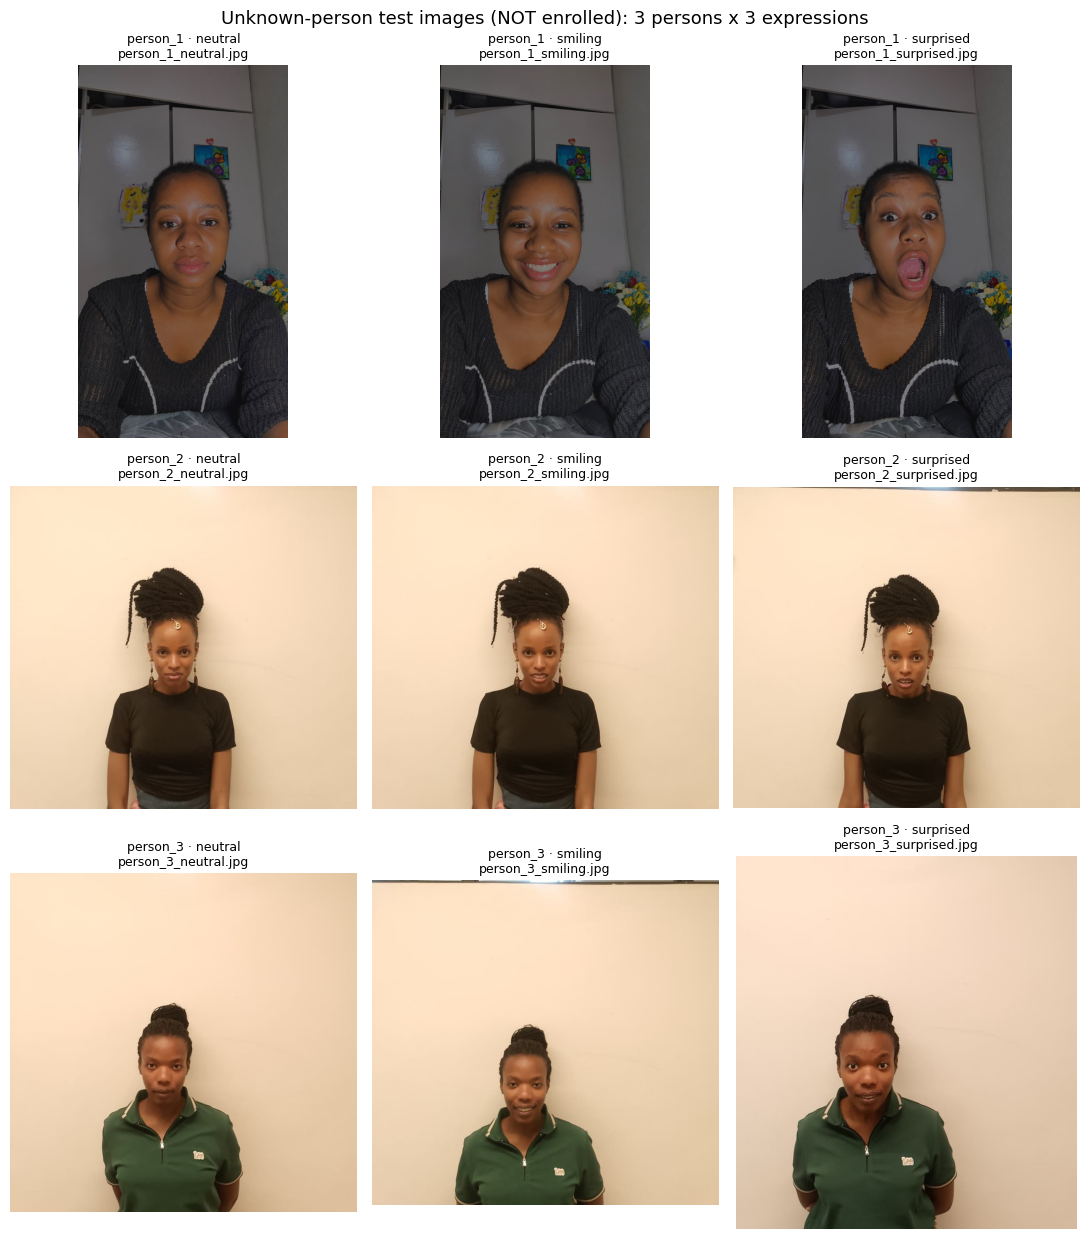

In [50]:
persons = sorted(unk_inspection.person_id.dropna().unique())
fig, axes = plt.subplots(len(persons), 3, figsize=(11, 4.2 * len(persons)), squeeze=False)
for i, p in enumerate(persons):
    for j, e in enumerate(EXPRESSIONS):
        ax = axes[i][j]; ax.axis("off")
        row = unk_inspection[(unk_inspection.person_id == p) & (unk_inspection.expression == e)]
        if row.empty:
            ax.set_title(f"{p} / {e}\nMISSING", color="red"); continue
        r = row.iloc[0]
        try:
            ax.imshow(load_image_rgb(r.path, max_side=700)); ax.set_title(f"{r.person_id} · {r.expression}\n{r.image_filename}", fontsize=9)
        except ValueError:
            ax.set_title(f"{p} / {e}\nUNREADABLE", color="red")
fig.suptitle("Unknown-person test images (NOT enrolled): 3 persons x 3 expressions", fontsize=13)
plt.tight_layout(); savefig("10_unknown_person_images.png"); plt.show()

### 11.3 Preprocessing, embedding extraction and verification

Each unknown image is passed through the **same preprocessing pipeline used for the enrolled images**. The `fx.get_embedding` function applies the configured face-processing steps, including RetinaFace detection, facial landmark alignment, face cropping and resizing to **160 × 160 pixels**, before extracting a FaceNet512 embedding.

FaceNet512 represents each processed face as a **512-dimensional vector**. The vector is compared with the three saved enrolled-member templates using cosine similarity. The highest similarity score is then checked against the fixed **0.70 threshold**:

- A score of **0.70 or above** produces an `ACCEPTED` decision.
- A score **below 0.70** produces a `REJECTED` decision.

The closest enrolled identity is recorded to show which template produced the highest score, but the closest match alone does not mean that the person is authorised. The threshold determines the decision.

Every image is accounted for. A missing file, unreadable image, failed face detection or failed embedding is recorded with its reason and is **not** treated as a successful rejection. The aligned 160 × 160 crops are saved to `outputs/unknown_processed_images/`, separately from the enrolled crops.

The saved templates are read for comparison and are not updated with the unknown-person images.

In [51]:
embed_fn = lambda rgb: fx.get_embedding(rgb, cfg)           # identical pipeline to the enrolled images
fmt_s = lambda x: "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.4f}"

jobs = [(r.person_id, r.expression, r.image_filename, r.path) for r in unk_inspection.itertuples()]
jobs += [(p, e, f"{p}_{e}.jpg", str(UNKNOWN_DIR / p / f"{p}_{e}.jpg")) for p, e in missing_unknown]   # missing files are reported, not skipped

records = []
for person, expr, fname, path in jobs:
    res = ut.evaluate_unknown_image(path, embed_fn, verifier.templates, verifier.member_ids, THRESHOLD, cfg["max_image_side"])
    rec = dict(person_id=person, expression=expr, image_filename=fname, path=path, **res, crop_path=None, crop_error="")
    if rec["status"] == ut.STATUS_OK:
        try:
            crop = UNKNOWN_CROP_DIR / person / f"{Path(fname).stem}_face160.jpg"
            fx.save_aligned_crop(load_image_rgb(path, cfg["max_image_side"]), crop, cfg); rec["crop_path"] = str(crop)
        except Exception as exc:                              # crop is for visual QA only; the decision above is unaffected
            rec["crop_error"] = f"{type(exc).__name__}: {str(exc)[:120]}"
    records.append(rec)
    print(f"{fname:<28} {ut.detection_status_text(rec):<42} best={fmt_s(rec['best_score'])} closest={rec['best_match'] or 'n/a':<9} -> {rec['decision']} / {rec['outcome']}")

unknown_results = pd.DataFrame(records)
unknown_results["face_detection"] = unknown_results.apply(ut.detection_status_text, axis=1)
if (unknown_results.status == "model_unavailable").all():
    print("\n*** NO IMAGE COULD BE PROCESSED: the face model is unavailable in this kernel (see the Section 2 preflight message). "
          "No rejection or acceptance is reported below. ***")
elif (unknown_results.status != ut.STATUS_OK).any():
    print(f"\n*** {int((unknown_results.status != ut.STATUS_OK).sum())} image(s) FAILED and are excluded from the metrics (listed in the table below). ***")

person_1_neutral.jpg         Detected (1 face, confidence 1.00)         best=0.5743 closest=member_3  -> REJECTED / CORRECT REJECTION
person_1_smiling.jpg         Detected (1 face, confidence 1.00)         best=0.6265 closest=member_3  -> REJECTED / CORRECT REJECTION
person_1_surprised.jpg       Detected (1 face, confidence 1.00)         best=0.3610 closest=member_3  -> REJECTED / CORRECT REJECTION
person_2_neutral.jpg         Detected (1 face, confidence 1.00)         best=0.5007 closest=member_1  -> REJECTED / CORRECT REJECTION
person_2_smiling.jpg         Detected (1 face, confidence 1.00)         best=0.5092 closest=member_1  -> REJECTED / CORRECT REJECTION
person_2_surprised.jpg       Detected (1 face, confidence 1.00)         best=0.4709 closest=member_1  -> REJECTED / CORRECT REJECTION
person_3_neutral.jpg         Detected (1 face, confidence 1.00)         best=0.5654 closest=member_1  -> REJECTED / CORRECT REJECTION
person_3_smiling.jpg         Detected (1 face, confidence 1.00

### 11.4 Verification result for each unknown image

The results table reports the outcome for each of the nine unknown-person images. It includes the filename, person and expression labels, face-detection or processing status, highest cosine similarity score, closest enrolled identity and final threshold decision.

Because these three people are known not to be enrolled:

- An image marked **REJECTED** is a correct rejection.
- An image marked **ACCEPTED** is a false acceptance.
- An image that could not be processed is recorded as a failure and is not counted as either a correct rejection or a false acceptance.

The closest enrolled identity is included for analysis only. The system should not grant access based on the closest identity unless the highest similarity score also meets the 0.70 threshold.

In [52]:
view = pd.DataFrame({
    "image_filename": unknown_results.image_filename,
    "person_id": unknown_results.person_id,
    "face_detection": unknown_results.face_detection,
    "highest_similarity": unknown_results.best_score.map(lambda x: "n/a" if pd.isna(x) else round(float(x), 4)),
    "closest_enrolled_identity": unknown_results.best_match.fillna("n/a"),
    "decision (threshold 0.70)": unknown_results.decision,
    "outcome (truth = not enrolled)": unknown_results.outcome,
})
display(view)
if (unknown_results.error != "").any():
    print("Failure details:"); display(unknown_results.loc[unknown_results.error != "", ["image_filename", "status", "error"]])
if (unknown_results.crop_error != "").any():
    print("Crop-saving problems (decisions unaffected):"); display(unknown_results.loc[unknown_results.crop_error != "", ["image_filename", "crop_error"]])
print("Per-person summary:"); display(ut.per_person_summary(unknown_results))

,image_filename,person_id,face_detection,highest_similarity,closest_enrolled_identity,decision (threshold 0.70),outcome (truth = not enrolled)
0,person_1_neutral.jpg,person_1,"Detected (1 face, confidence 1.00)",0.5743,member_3,REJECTED,CORRECT REJECTION
1,person_1_smiling.jpg,person_1,"Detected (1 face, confidence 1.00)",0.6265,member_3,REJECTED,CORRECT REJECTION
2,person_1_surprised.jpg,person_1,"Detected (1 face, confidence 1.00)",0.3610,member_3,REJECTED,CORRECT REJECTION
3,person_2_neutral.jpg,person_2,"Detected (1 face, confidence 1.00)",0.5007,member_1,REJECTED,CORRECT REJECTION
4,person_2_smiling.jpg,person_2,"Detected (1 face, confidence 1.00)",0.5092,member_1,REJECTED,CORRECT REJECTION
5,person_2_surprised.jpg,person_2,"Detected (1 face, confidence 1.00)",0.4709,member_1,REJECTED,CORRECT REJECTION
6,person_3_neutral.jpg,person_3,"Detected (1 face, confidence 1.00)",0.5654,member_1,REJECTED,CORRECT REJECTION
7,person_3_smiling.jpg,person_3,"Detected (1 face, confidence 1.00)",0.6205,member_1,REJECTED,CORRECT REJECTION
8,person_3_surprised.jpg,person_3,"Detected (1 face, confidence 1.00)",0.5060,member_1,REJECTED,CORRECT REJECTION


Per-person summary:


,person_id,n_images,n_processed,n_failed,correct_rejections,false_acceptances,highest_score,closest_identity_at_highest
0,person_1,3,3,0,3,0,0.6265,member_3
1,person_2,3,3,0,3,0,0.5092,member_1
2,person_3,3,3,0,3,0,0.6205,member_1


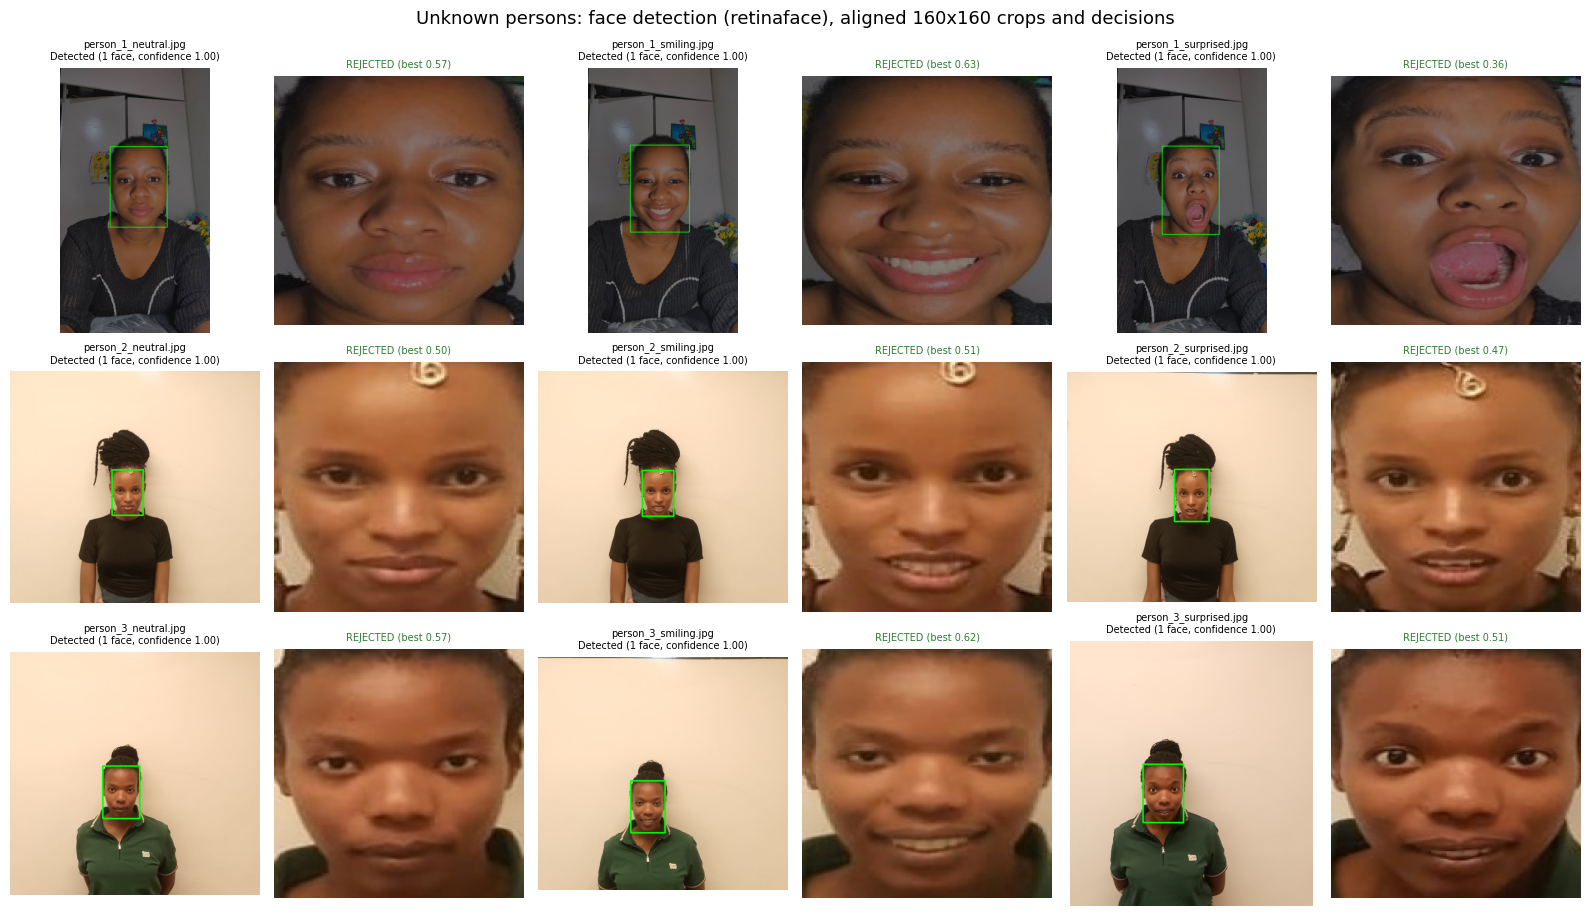

In [53]:
# Face detection boxes and aligned 160x160 crops for the unknown persons (same style as the enrolled-image figure 03)
n = len(unknown_results); nrows = int(np.ceil(n / 3))
fig, axes = plt.subplots(nrows, 6, figsize=(16, 3.1 * nrows), squeeze=False)
for k, r in enumerate(unknown_results.itertuples()):
    i, j = divmod(k, 3); a_img, a_crop = axes[i][2 * j], axes[i][2 * j + 1]
    if r.status == "file_missing":
        a_img.text(0.5, 0.5, "MISSING", ha="center", color="red"); a_img.set_title(r.image_filename, fontsize=7); continue
    try:
        rgb = load_image_rgb(r.path, cfg["max_image_side"])
    except ValueError:
        a_img.text(0.5, 0.5, "UNREADABLE", ha="center", color="red"); a_img.set_title(r.image_filename, fontsize=7); continue
    boxed = rgb.copy()
    if r.face_detected and not pd.isna(r.face_x):
        cv2.rectangle(boxed, (int(r.face_x), int(r.face_y)), (int(r.face_x + r.face_w), int(r.face_y + r.face_h)), (0, 255, 0), max(2, rgb.shape[1] // 200))
    a_img.imshow(boxed); a_img.set_title(f"{r.image_filename}\n{r.face_detection}", fontsize=7, color="k" if r.status == ut.STATUS_OK else "red")
    if isinstance(r.crop_path, str):
        a_crop.imshow(load_image_rgb(r.crop_path))
        a_crop.set_title(f"{r.decision} (best {r.best_score:.2f})", fontsize=7, color="#2E7D32" if r.decision == ut.DECISION_REJECTED else "#C62828")
    else:
        a_crop.set_title("no aligned crop", fontsize=7, color="red")
for a in axes.flat: a.axis("off")
fig.suptitle(f"Unknown persons: face detection ({cfg['detector_backend']}), aligned 160x160 crops and decisions", fontsize=13)
plt.tight_layout(); savefig("11_unknown_person_detection_and_crops.png"); plt.show()

### 11.5 Consistency check and data-leakage check

Two checks are carried out before the unknown-person metrics are calculated.

1. **Consistency with the saved verification function.** Each unknown image is also passed through the saved `verify_face()` function. Its accept/reject decision is compared with the decision produced in the results table. The two decisions should agree because they use the same saved model and threshold.
2. **No data leakage.** The saved templates, template file and enrolled feature table are checked against their state before the unknown-person images were processed. The unknown images must not appear in the enrolled feature table, and the enrolled templates must remain unchanged.

These checks matter because the purpose of this stage is to test the existing system with people who are not registered. If their images were added to the enrolled data or used to update the templates, the test would no longer be independent. Any failed consistency or leakage check is reported rather than being treated as a successful test.

In [54]:
from src.face_model import verify_face
chk = []
for r in unknown_results.itertuples():
    v = verify_face(r.path)
    chk.append(dict(image=r.image_filename, pipeline_decision=r.decision, verify_face_verified=v["verified"], verify_face_status=v["status"],
                    verify_face_score=v["score"], agrees=(None if r.status != ut.STATUS_OK else (r.decision == ut.DECISION_ACCEPTED) == bool(v["verified"]))))
chk = pd.DataFrame(chk)
comparable = chk[chk.agrees.notna()]
print(f"verify_face() agrees with the notebook decision for {int(comparable.agrees.sum())} of {len(comparable)} processed unknown images.")
if len(comparable) and not comparable.agrees.all():
    print("DISAGREEMENTS (investigate before using the results):"); display(comparable[~comparable.agrees.astype(bool)])
if (chk.verify_face_status == "model_unavailable").any():
    print("verify_face() reported model_unavailable for at least one image.")

# ---- leakage guard 2: nothing that defines the enrolled identities may have changed ----
verifier_after = fm.FaceVerifier.load()
snap_after = dict(
    templates_array_sha=_sha(verifier_after.templates),
    templates_file_sha=sha256_of(MODEL_DIR / "face_templates.npy"),
    features_csv_sha=sha256_of(PROC_DIR / "image_features.csv") if (PROC_DIR / "image_features.csv").exists() else None)
unknown_names = set(unknown_results.image_filename)
leak_checks = {
    "templates in memory unchanged":                        bool(np.array_equal(templates_saved, verifier.templates)),
    "templates array hash unchanged (before == after)":     snap_before["templates_array_sha"] == snap_after["templates_array_sha"],
    "face_templates.npy file hash unchanged":               snap_before["templates_file_sha"] == snap_after["templates_file_sha"],
    "templates hash == templates_sha256 in metadata":       snap_after["templates_array_sha"] == meta_saved["templates_sha256"],
    "image_features.csv hash unchanged":                    snap_before["features_csv_sha"] == snap_after["features_csv_sha"],
    "enrolled feature rows unchanged":                      len(features) == n_features_before,
    "no unknown filename in enrolled feature table":        not (unknown_names & set(features.image_filename)),
    "only enrolled members in feature table":               set(features.member_id) == set(MEMBERS),
    "unknown crops stored apart from enrolled crops":       all(str(p).startswith(str(UNKNOWN_CROP_DIR)) for p in unknown_results.crop_path.dropna()),
}
display(pd.Series(leak_checks, name="passed").map({True: "PASS", False: "FAIL"}).to_frame())
assert all(leak_checks.values()), "Data-leakage check FAILED: see the table above."
print("All leakage checks passed: unknown-person images were never added to the enrolled data or the templates.")

verify_face() agrees with the notebook decision for 9 of 9 processed unknown images.


,passed
templates in memory unchanged,PASS
templates array hash unchanged (before == after),PASS
face_templates.npy file hash unchanged,PASS
templates hash == templates_sha256 in metadata,PASS
image_features.csv hash unchanged,PASS
enrolled feature rows unchanged,PASS
no unknown filename in enrolled feature table,PASS
only enrolled members in feature table,PASS
unknown crops stored apart from enrolled crops,PASS


All leakage checks passed: unknown-person images were never added to the enrolled data or the templates.


### 11.6 Extended model evaluation

The evaluation was expanded to include three sets of results. Each one serves a different purpose:

| **Evaluation** | **Samples** | **Purpose** |
|---|---|---|
| **Initial evaluation (Section 10)** | 9 genuine probes and 9 leave-one-member-out probes | Checks whether enrolled members are correctly recognised and whether their images are rejected when they are not included in the reference templates. |
| **Unknown-person test** | Images from 3 people who were not enrolled | Checks whether the system rejects people whose face templates are not stored in the system. |
| **Combined evaluation** | Samples from the initial evaluation and the unknown-person test | Looks at how the system performs across all the genuine and unauthorised attempts. |

For the binary evaluation, genuine attempts are expected to be accepted, while unknown-person attempts are expected to be rejected.

The following terms are used to describe the results:

- **True Positive (TP):** A genuine attempt that is correctly accepted.
- **False Negative (FN):** A genuine attempt that is rejected or matched to the wrong member.
- **True Negative (TN):** An unknown-person attempt that is correctly rejected.
- **False Positive (FP):** An unknown-person attempt that is incorrectly accepted.

The evaluation metrics are calculated as follows:

- **FAR (False Acceptance Rate):** The proportion of unknown attempts that are incorrectly accepted.
- **FRR (False Rejection Rate):** The proportion of genuine attempts that are incorrectly rejected.
- **Accuracy:** The proportion of all attempts that receive the correct decision.
- **Precision:** How many accepted positive predictions are actually genuine attempts.
- **Recall:** The proportion of genuine attempts correctly accepted.
- **F1-score:** A measure that combines precision and recall.

**A few points to note when interpreting the results:**

- The unknown-person test contains only people who are not enrolled. It has no genuine attempts. For this reason, FAR and accuracy can be calculated, but FRR, precision, recall and F1-score are not applicable to this test and are shown as *n/a*.
- The combined evaluation includes the original genuine attempts and the additional unknown-person images. Since no new genuine attempts were added, the FRR and recall remain based on the initial evaluation. The additional unknown-person samples affect the FAR and precision.
- Any images that could not be processed are excluded from the calculations and reported separately.
- Although the unknown-person test contains 9 images, they come from only 3 individuals. Images of the same person may be very similar, so the results should not be treated as 9 completely independent tests. More participants are needed to draw stronger conclusions.
- **Loss is not reported** because the project uses the pretrained FaceNet512 model to extract facial embeddings. The model was not trained or fine-tuned as part of this work, so there is no training or validation loss to report.

In [55]:
E = ut.combined_evaluation(R, unknown_results, THRESHOLD, MEMBERS)
um, ini, unk_only, com = E["unknown_metrics"], E["initial"], E["unknown_only"], E["combined"]
ci_txt = lambda k, n_: "n/a" if not n_ else "[{:.2f}, {:.2f}]".format(*ev.wilson_interval(k, n_))

print(f"Threshold (cosine similarity): {THRESHOLD}")
print(f"Unknown test images          : {um['n_unknown_images']}  (processed: {um['n_processed']}, failed: {um['n_failed']})")
print(f"Correctly rejected           : {um['correct_rejections']}")
print(f"Incorrectly accepted (FA)    : {um['false_acceptances']}")
print(f"FAR (unknown persons)        : {fmt_s(um['FAR'])}   95% CI {ci_txt(um['false_acceptances'], um['n_processed'])}")
print(f"Highest / mean / lowest best-similarity among unknowns: {fmt_s(um['max_best_score'])} / {fmt_s(um['mean_best_score'])} / {fmt_s(um['min_best_score'])}")
print(f"Margin between the highest unknown score and the threshold: {fmt_s(um['margin_below_threshold'])} (negative = threshold exceeded)")
if um["n_processed"] == 0:
    print("\nNo unknown image was processed successfully, so NO unknown-person metric can be reported and the combined figures below equal the initial ones.")

s = lambda x: "n/a" if x is None else f"{x:.3f}"
comparison = pd.DataFrame({
    "Initial evaluation (enrolled members)": [ini["n"], ini["TP"], ini["FN"], ini["TN"], ini["FP"], s(ini["FAR"]), s(ini["FRR"]), s(ini["accuracy"]), s(ini["precision"]), s(ini["recall"]), s(ini["f1"])],
    "Unknown-person test": [unk_only["n"], "n/a", "n/a", unk_only["correct_rejections"], unk_only["false_acceptances"], s(unk_only["FAR"]), "n/a", s(unk_only["accuracy"]), "n/a", "n/a", "n/a"],
    "Combined": [com["n"], com["TP"], com["FN"], com["TN"], com["FP"], s(com["FAR"]), s(com["FRR"]), s(com["accuracy"]), s(com["precision"]), s(com["recall"]), s(com["f1"])],
}, index=["Samples evaluated", "Genuine accepted (TP)", "Genuine rejected (FN)", "Unknown rejected (TN)", "Unknown accepted (FP)",
          "FAR", "FRR", "Accuracy", "Precision", "Recall", "F1-score"])
print("\nAuthorised-versus-unauthorised metrics (binary view):")
display(comparison)
print(f"FAR 95% CI - unknown only: {ci_txt(unk_only['false_acceptances'], unk_only['n'])} | combined: {ci_txt(com['FP'], com['FP'] + com['TN'])}")
print(f"For reference, the Section 10 four-class results (unchanged): accuracy {R['open_set']['accuracy']:.3f}, macro F1 {R['open_set']['macro_f1']:.3f}, n={R['open_set']['n_samples']}")

four = E["combined_four_class"]
if four is not None:
    print(f"\nCombined four-class decision (3 members + unknown, n={four['n_samples']}): accuracy={four['accuracy']:.3f}, "
          f"macro precision={four['macro_precision']:.3f}, macro recall={four['macro_recall']:.3f}, macro F1={four['macro_f1']:.3f}")
    display(pd.DataFrame(four["per_class"]).round(3))

Threshold (cosine similarity): 0.7
Unknown test images          : 9  (processed: 9, failed: 0)
Correctly rejected           : 9
Incorrectly accepted (FA)    : 0
FAR (unknown persons)        : 0.0000   95% CI [0.00, 0.30]
Highest / mean / lowest best-similarity among unknowns: 0.6265 / 0.5260 / 0.3610
Margin between the highest unknown score and the threshold: 0.0735 (negative = threshold exceeded)

Authorised-versus-unauthorised metrics (binary view):


,Initial evaluation (enrolled members),Unknown-person test,Combined
Samples evaluated,18,9,27
Genuine accepted (TP),9,n/a,9
Genuine rejected (FN),0,n/a,0
Unknown rejected (TN),9,9,18
Unknown accepted (FP),0,0,0
FAR,0.000,0.000,0.000
FRR,0.000,n/a,0.000
Accuracy,1.000,1.000,1.000
Precision,1.000,n/a,1.000
Recall,1.000,n/a,1.000


FAR 95% CI - unknown only: [0.00, 0.30] | combined: [0.00, 0.18]
For reference, the Section 10 four-class results (unchanged): accuracy 1.000, macro F1 1.000, n=18

Combined four-class decision (3 members + unknown, n=27): accuracy=1.000, macro precision=1.000, macro recall=1.000, macro F1=1.000


,label,precision,recall,f1,support
0,member_1,1.0,1.0,1.0,3
1,member_2,1.0,1.0,1.0,3
2,member_3,1.0,1.0,1.0,3
3,unknown,1.0,1.0,1.0,18


### 11.7 Visualisations of the unknown-person results

- **Figure 12:** the highest similarity of each unknown image against the threshold, and how these scores compare with the genuine scores of the initial evaluation.
- **Figure 13:** the combined confusion matrix (3 members + *unknown*). A false acceptance appears as a count in the *unknown* row under a member column.
- **Figure 14:** a comparison of the initial, unknown-person and combined results.

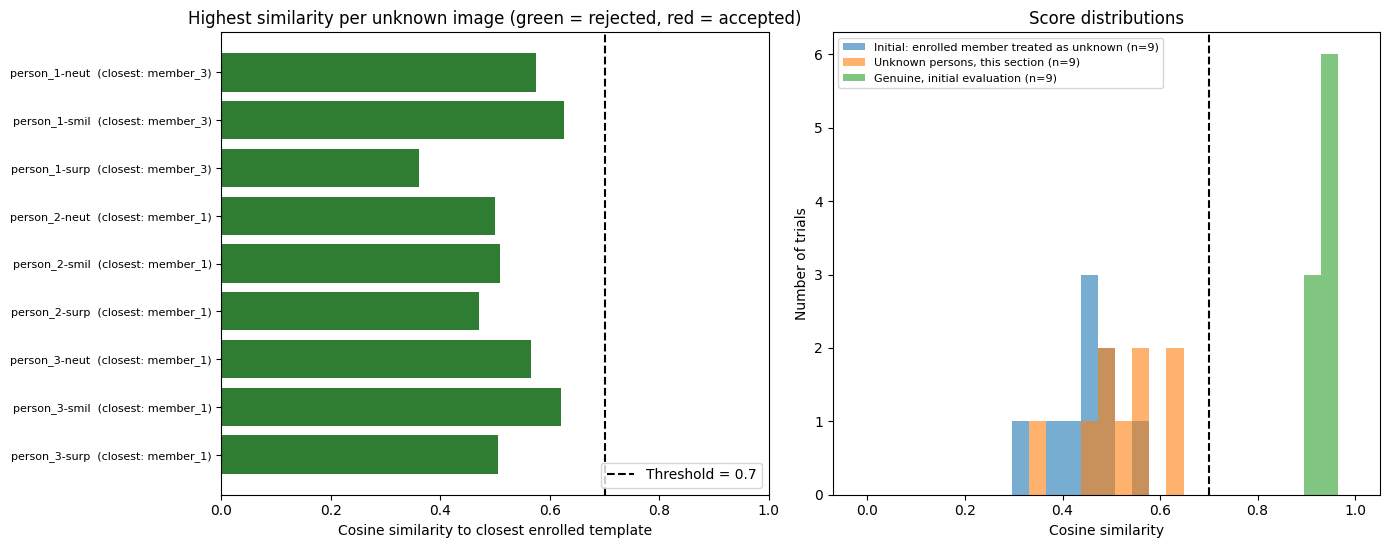

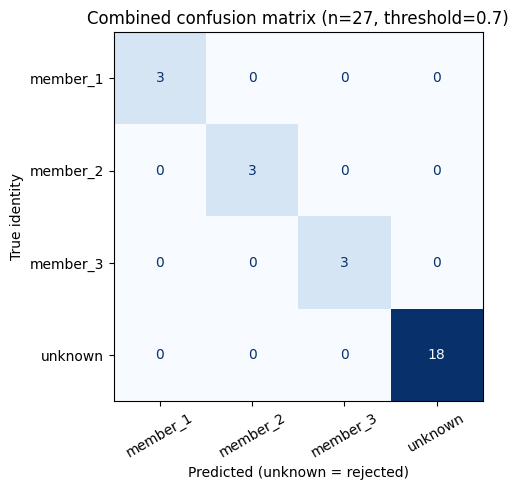

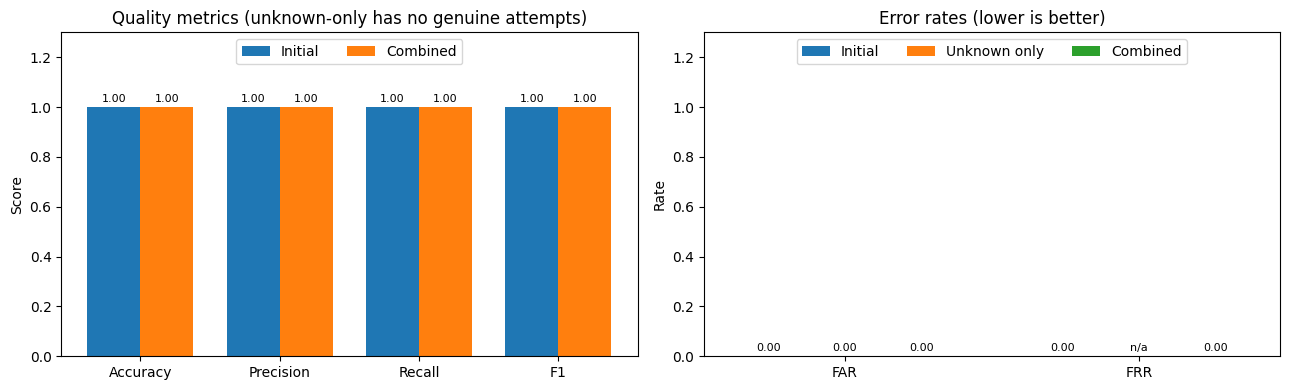

In [56]:
ok = unknown_results[unknown_results.status == ut.STATUS_OK].sort_values(["person_id", "expression"])
if ok.empty:
    print("No processed unknown images: figures 12-14 are skipped.")
else:
    # ---- Figure 12: per-image scores and distribution comparison ----
    gen = [getattr(r, f"score_{r.true_id}") for r in R["loeo"].itertuples()]
    lomo_scores = R["unknown"]["score"].tolist()
    fig, ax = plt.subplots(1, 2, figsize=(14, max(4.2, 0.42 * len(ok) + 1.8)))
    ypos = np.arange(len(ok))
    ax[0].barh(ypos, ok.best_score, color=["#2E7D32" if d == ut.DECISION_REJECTED else "#C62828" for d in ok.decision])
    ax[0].set_yticks(ypos, [f"{r.person_id}-{r.expression[:4]}  (closest: {r.best_match})" for r in ok.itertuples()], fontsize=8); ax[0].invert_yaxis()
    ax[0].axvline(THRESHOLD, color="k", ls="--", label=f"Threshold = {THRESHOLD}"); ax[0].set_xlim(min(0, ok.best_score.min() - 0.05), 1)
    ax[0].set(title="Highest similarity per unknown image (green = rejected, red = accepted)", xlabel="Cosine similarity to closest enrolled template"); ax[0].legend(loc="lower right")
    bins = np.linspace(min(gen + lomo_scores + ok.best_score.tolist() + [0]) - 0.02, 1.0, 30)
    ax[1].hist(lomo_scores, bins, alpha=.6, label=f"Initial: enrolled member treated as unknown (n={len(lomo_scores)})")
    ax[1].hist(ok.best_score, bins, alpha=.6, label=f"Unknown persons, this section (n={len(ok)})")
    ax[1].hist(gen, bins, alpha=.6, label=f"Genuine, initial evaluation (n={len(gen)})")
    ax[1].axvline(THRESHOLD, color="k", ls="--"); ax[1].set(title="Score distributions", xlabel="Cosine similarity", ylabel="Number of trials"); ax[1].legend(fontsize=8)
    plt.tight_layout(); savefig("12_unknown_person_scores.png"); plt.show()

    # ---- Figure 13: combined confusion matrix ----
    from sklearn.metrics import ConfusionMatrixDisplay
    fig, ax = plt.subplots(figsize=(5.8, 5.0))
    ConfusionMatrixDisplay(np.array(four["confusion_matrix"]), display_labels=four["labels"]).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
    ax.set(title=f"Combined confusion matrix (n={four['n_samples']}, threshold={THRESHOLD})", xlabel="Predicted (unknown = rejected)", ylabel="True identity")
    plt.tight_layout(); savefig("13_combined_confusion_matrix.png"); plt.show()

    # ---- Figure 14: initial vs unknown-person vs combined ----
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    names = ["accuracy", "precision", "recall", "f1"]; x = np.arange(len(names)); w = 0.38
    for k, (lab, d) in enumerate([("Initial", ini), ("Combined", com)]):
        vals = [np.nan if d[m] is None else d[m] for m in names]
        bars = ax[0].bar(x + (k - .5) * w, np.nan_to_num(vals), w, label=lab)
        for b, v in zip(bars, vals): ax[0].text(b.get_x() + b.get_width() / 2, (0 if np.isnan(v) else v) + .02, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", fontsize=8)
    ax[0].set_xticks(x, ["Accuracy", "Precision", "Recall", "F1"]); ax[0].set_ylim(0, 1.3); ax[0].legend(loc="upper center", ncol=2); ax[0].set(title="Quality metrics (unknown-only has no genuine attempts)", ylabel="Score")
    errs = ["FAR", "FRR"]; x2 = np.arange(2); w2 = 0.26
    for k, (lab, d) in enumerate([("Initial", ini), ("Unknown only", unk_only), ("Combined", com)]):
        vals = [np.nan if d[m] is None else d[m] for m in errs]
        bars = ax[1].bar(x2 + (k - 1) * w2, np.nan_to_num(vals), w2, label=lab)
        for b, v in zip(bars, vals): ax[1].text(b.get_x() + b.get_width() / 2, (0 if np.isnan(v) else v) + .02, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", fontsize=8)
    ax[1].set_xticks(x2, errs); ax[1].set_ylim(0, 1.3); ax[1].legend(loc="upper center", ncol=3); ax[1].set(title="Error rates (lower is better)", ylabel="Rate")
    plt.tight_layout(); savefig("14_initial_vs_unknown_vs_combined.png"); plt.show()


### Interpreting the Unknown-Person Results

The unknown-person test evaluates whether the system can distinguish people who are not enrolled from those whose face templates are stored in the system.

- **Correct rejection:** An unknown person's image is rejected because its similarity score is below the 0.70 acceptance threshold.
- **False acceptance:** An unknown person's image is accepted because its similarity score meets or exceeds the threshold. This means the system incorrectly identifies an unenrolled person as an enrolled member.
- **Processing failure:** An image that cannot be processed successfully is excluded from the evaluation metrics. It is neither a correct rejection nor an acceptance.

The distance between the highest unknown-person similarity score and the acceptance threshold also helps show how close the system came to a false acceptance.



### Observed Unknown-Person Results

**Unknown-person test:** 9 images from 3 unenrolled people were supplied. All 9 images were successfully processed, with no failures.

All 9 processed images were **rejected correctly**. The highest similarity score against any enrolled template was **0.626**, recorded for `person_1_smiling.jpg`, whose closest match was `member_3`. This score was **0.074 below the 0.70 acceptance threshold**.

The false acceptance rate (FAR) was **0.000**, with a 95% confidence interval of **[0.00, 0.30]**. No unknown-person image was incorrectly accepted as an enrolled member.

### Combined Evaluation

The combined evaluation, covering the initial verification and unknown-person test (n = 27), produced the following results:

| Metric | Result |
|---|---:|
| Accuracy | 1.000 |
| Precision | 1.000 |
| Recall | 1.000 |
| F1-score | 1.000 |
| False Acceptance Rate (FAR) | 0.000 |
| False Rejection Rate (FRR) | 0.000 |

Since the unknown-person test introduced no new genuine verification attempts, the FRR and recall values remain based on the initial evaluation.

**Limitation:** Only 3 unknown individuals were tested in this project. Each individual provided 3 photographs. The data collected from this would be very limited meaning that the results cannot be used to prove the systems reliability or security within real life situations. This provides further evidence into how the system reacted to the photographs used within this experiment.

In [61]:
# ---- save results (scores and decisions only; no images or embeddings) ----
unknown_results.drop(columns=["path", "face_x", "face_y", "face_w", "face_h"]).to_csv(EVAL_DIR / "unknown_person_results.csv", index=False)
comparison.to_csv(EVAL_DIR / "unknown_person_comparison_table.csv")
(EVAL_DIR / "unknown_person_metrics.json").write_text(json.dumps(
    {"threshold": THRESHOLD, "unknown_person_test": um, "initial_binary": ini, "unknown_only": unk_only, "combined_binary": com,
     "combined_four_class": four, "leakage_checks": leak_checks}, indent=2, default=str), encoding="utf-8")
(EVAL_DIR / "unknown_person_summary.md").write_text("# Unknown-person verification summary (auto-generated by the notebook)\n\n"
    f"Generated: {datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')} UTC | model: {cfg['model_name']} | detector: {cfg['detector_backend']} | threshold: {THRESHOLD}\n\n"
    + summary_md + "\n", encoding="utf-8")
print("Saved: unknown_person_results.csv, unknown_person_comparison_table.csv, unknown_person_metrics.json, unknown_person_summary.md ->", EVAL_DIR)

Saved: unknown_person_results.csv, unknown_person_comparison_table.csv, unknown_person_metrics.json, unknown_person_summary.md -> outputs/evaluation


### Limitations of the unknown-person test

**Only 3 people are in the dataset**. There are 3 unknowns. The 3 photos aren’t independent. So overall there’s effectively only 3 tests.

**No data augmentation**. The data augmentation increases the size of the training data but doesn’t increase the number of independent people. No data augmentation was used on the unknowns.

**Restricted dataset**. There wasn’t a variety of sessions, lighting, cameras and poses. There may be differences between the backgrounds and cameras for different people which can affect the embeddings.

**No spoof/liveness detection**. No demographic fairness analysis.

**Threshold was pre-set**. Threshold of 0.70 wasn’t tuned on this data. In a real system it would be calibrated using a much larger consensual dataset.

**Unknowns don’t give any indication of the systems performance on this data**. They just give additional evidence. They don’t provide any indication of how secure this would be in real life scenarios.

## 12. Visualisations and results

The following figures present the similarity patterns and evaluation outcomes in visual form. They complement the numerical results printed in the evaluation section.

The notebook also saves the figures in `outputs/figures/`. The earlier figures cover the original dataset, image distribution, face detection and augmentation examples. The figures below focus on embedding similarity, score distributions, classification decisions and the FAR/FRR threshold trade-off.

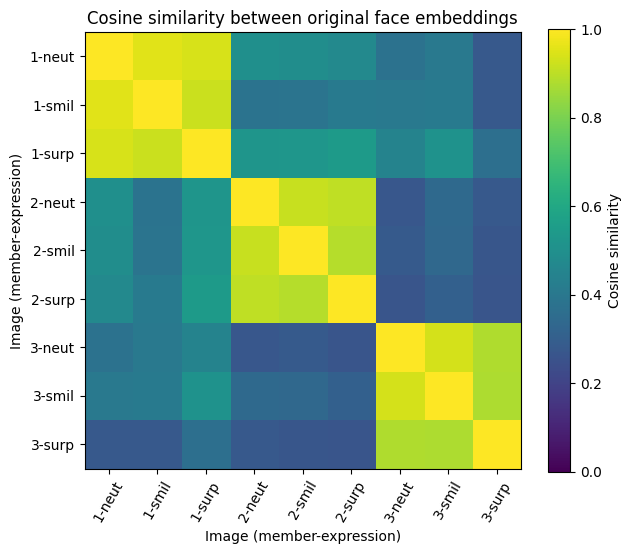

In [58]:
# 05 - similarity heat-map between the nine ORIGINAL embeddings
orig = features[features.is_original].sort_values(["member_id", "expression"])
E = ev.l2_normalize(orig[emb_cols].to_numpy()); S = E @ E.T
labels = [f"{r.member_id[-1]}-{r.expression[:4]}" for r in orig.itertuples()]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(S, vmin=0, vmax=1, cmap="viridis"); plt.colorbar(im, label="Cosine similarity")
ax.set_xticks(range(len(labels)), labels, rotation=60); ax.set_yticks(range(len(labels)), labels)
ax.set(title="Cosine similarity between original face embeddings", xlabel="Image (member-expression)", ylabel="Image (member-expression)")
plt.tight_layout(); savefig("05_embedding_similarity_heatmap.png"); plt.show()

**Similarity heat-map interpretation**

The heat-map compares the embeddings from the nine original photographs. The diagonal blocks represent comparisons between images of the same member, while the off-diagonal blocks represent comparisons between different members.

The three within-member blocks show stronger similarity than the between-member comparisons. This visual pattern is consistent with the evaluation result, where the genuine scores are higher than the enrolled-impostor and unknown-person scores. The heat-map is based on the nine original images and is descriptive of this dataset only.

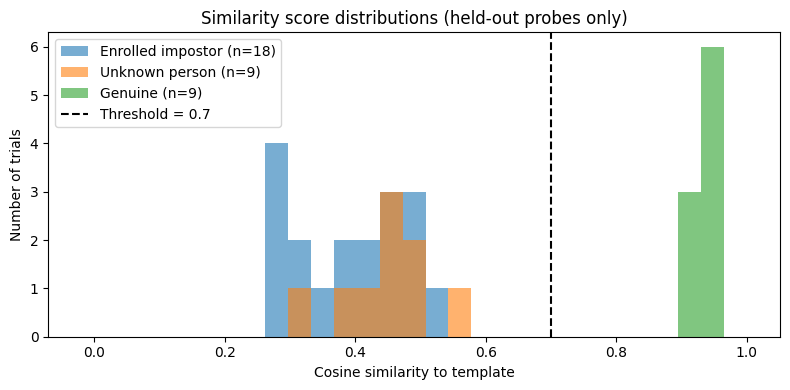

In [59]:
# 06 - score distributions and threshold
gen = [getattr(r, f"score_{r.true_id}") for r in R["loeo"].itertuples()]
imp = [getattr(r, f"score_{m}") for r in R["loeo"].itertuples() for m in MEMBERS if m != r.true_id]
unk = R["unknown"]["score"].tolist()
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(min(gen + imp + unk + [0]) - 0.02, 1.0, 30)
ax.hist(imp, bins, alpha=.6, label=f"Enrolled impostor (n={len(imp)})"); ax.hist(unk, bins, alpha=.6, label=f"Unknown person (n={len(unk)})")
ax.hist(gen, bins, alpha=.6, label=f"Genuine (n={len(gen)})"); ax.axvline(THRESHOLD, color="k", ls="--", label=f"Threshold = {THRESHOLD}")
ax.set(title="Similarity score distributions (held-out probes only)", xlabel="Cosine similarity to template", ylabel="Number of trials"); ax.legend()
plt.tight_layout(); savefig("06_score_distributions.png"); plt.show()

**Score distribution interpretation**

The score distribution compares genuine scores with enrolled-impostor and unknown-person scores. The dashed vertical line marks the configured cosine-similarity threshold of **0.70**.

In this run, the genuine scores are above the threshold, while the impostor and unknown-person scores are below it. This agrees with the reported counts of 9 accepted genuine trials and 27 rejected impostor/unknown trials.

The clear separation is encouraging, but the number of trials is small. A larger and more varied dataset is needed before drawing conclusions about performance in other conditions or with other people.

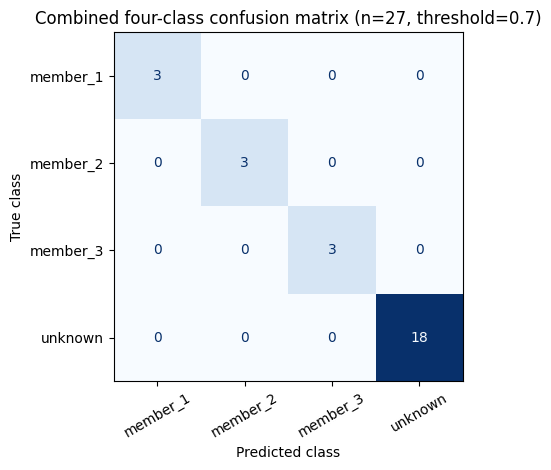

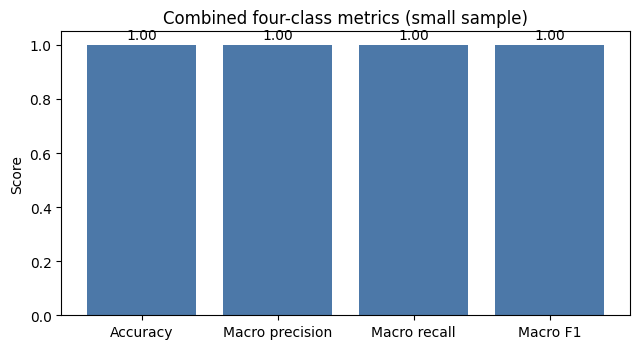

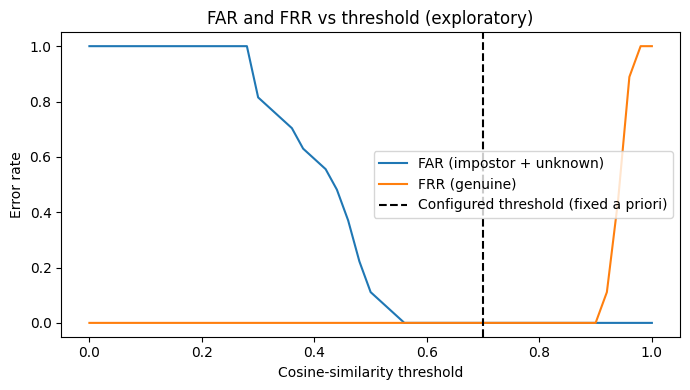

In [62]:

# 07 - Combined four-class confusion matrix; 08 - metric summary

from sklearn.metrics import ConfusionMatrixDisplay
import json

# Load the saved evaluation results
with open(EVAL_DIR / "unknown_person_metrics.json", "r", encoding="utf-8") as f:
    evaluation_data = json.load(f)

four = evaluation_data.get("combined_four_class")

if four is None:
    print("Combined four-class evaluation is not available. Run Section 11.6 first.")
else:
    cm = np.asarray(four["confusion_matrix"])
    labels = four["labels"]

    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30
    )
    ax.set(
        title=f"Combined four-class confusion matrix (n={four['n_samples']}, threshold={THRESHOLD})",
        xlabel="Predicted class",
        ylabel="True class"
    )
    plt.tight_layout()
    savefig("07_confusion_matrix.png")
    plt.show()

    vals = {
        "Accuracy": four["accuracy"],
        "Macro precision": four["macro_precision"],
        "Macro recall": four["macro_recall"],
        "Macro F1": four["macro_f1"]
    }

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.bar(vals.keys(), vals.values(), color="#4C78A8")
    ax.set_ylim(0, 1.05)

    for i, value in enumerate(vals.values()):
        ax.text(i, value + .02, f"{value:.2f}", ha="center")

    ax.set(title="Combined four-class metrics (small sample)", ylabel="Score")
    plt.tight_layout()
    savefig("08_metric_summary.png")
    plt.show()


# 09 - FAR / FRR vs threshold (EXPLORATORY)

sw = R["sweep"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sw.threshold, sw.FAR, label="FAR (impostor + unknown)")
ax.plot(sw.threshold, sw.FRR, label="FRR (genuine)")
ax.axvline(
    THRESHOLD,
    color="k",
    ls="--",
    label="Configured threshold (fixed a priori)"
)
ax.set(
    title="FAR and FRR vs threshold (exploratory)",
    xlabel="Cosine-similarity threshold",
    ylabel="Error rate"
)
ax.legend()
plt.tight_layout()
savefig("09_far_frr_vs_threshold.png")
plt.show()


**Classification and threshold interpretation**

The four-class confusion matrix gives a summary of the final classifications made in this example. The diagonal represents correct classifications. Any value which is not on the diagonal indicate incorrect decisions. In particular, if an unknown image is assigned to one of the three member classes, this is an example of a false acceptance. An unenrolled individual has been accepted as one of the enrolled individuals.


The metric summary provides information about the overall accuracy, macro precision, macro recall and macro F1 score of this scenario. However, to truly understand how well the classifications are performing, these metrics should be considered alongside the FAR and FRR.


The threshold sweep plot displays how the FAR and FRR respond when altering the threshold value used in the cosine similarity function. By increasing the threshold, we are making the acceptance conditions more strict. Whilst this can decrease the false acceptance rates, it can also increase the false reject rate if genuine enrolled members receive a lower score.


These results are based on the small sample size used in this example. We cannot determine how the system would perform with a larger population or different capture conditions.


# Evaluation Summary and Discussion

### 1. Initial Verification Test

The initial evaluation tested how well the system could verify if a trial was from an enrolled member. This was achieved by using FaceNet512 to extract the facial embedding. The extracted embeddings were then compared to find an identity match using cosine similarity. If the similarity was above 0.70 then the identity was accepted.



The initial evaluation had a closed set top 1 accuracy of 1.000. All genuine trials were correctly accepted and any enrolled impostor and previous unknown probes were rejected. This lead to a False Acceptance Rate (FAR) and False Rejection Rate (FRR) of 0.000.



The initial 4 class evaluation had an accuracy of 1.000. It also had a macro F1 score of 1.000. This should be viewed in context as there was a small amount of data available and few participants.


### 2. Unknown-Person Verification

The unknown person test consisted of 3 people with 3 photos each. This resulted in 9 unknown person images.

All 9 images were processed and rejected. The highest similarity score was 0.626, from the image ‘person_1_smiling.jpg’ which had the closest match of ‘member_3’. This was still below the threshold of 0.70 by 0.074.


There was a FAR of 0.000 from this unknown person test. This shows that none of the unknown person images were falsely accepted. This proves that the system was able to identify the unknown individuals tested were not enrolled.


### 3. Combined Evaluation

This evaluation included all images, the initial verification images and the extra unknown person images. This resulted in a total of 27 evaluation images.


The results were:


| Metric | Result |
|---|---:|
| Accuracy | 1.000 |
| Precision | 1.000 |
| Recall | 1.000 |
| F1-score | 1.000 |
| False Acceptance Rate (FAR) | 0.000 |
| False Rejection Rate (FRR) | 0.000 |

This shows that all verification were correctly classifed. This is because the unknown person images were not added to the enrolled dataset but were compared to the existing enrolled templates. The FRR and Recall are still based on the initial verification images as there were no extra genuine trials.

### 4. Limitations and Considerations

Even though the evaluation had perfect results, this does not mean the system has a secure and reliable performance in the real world.

As there were only 3 enrolled members and 3 unknown people in the dataset, along with a small amount of images, this does not provide enough data to know how the system will perform in a larger and more varied population. It also cannot tell us how it will perform in different lighting, camera, pose and environmental conditions.

There is no liveness detection or presentation attack detection. This means the system has not been tested with images, screens or any spoofing.

The confidence interval for the unknown person FAR is quite large due to there being very few unknown person test images.

### 5. Overall Discussion

The experiment shows the full process of processing images and verifying faces. This includes preparing images, detecting faces, extracting facial embeddings, comparing similarities and verifying identities.

The extra unknown person test provides an extension to the evaluation. This shows that the system can reject people whose templates aren’t stored.

Overall, the results are positive from this controlled experiment. However, the system needs to be tested with more people, extra capture conditions and independent test images before it can be considered suitable for verifying identities in the real world.

**Note:** There is no loss as the embedding extraction is done using a pre-trained FaceNet512 model. No new classification model was trained in this experiment. The verification was done using cosine similarity.


## Conclusion

A facial recognition application using image processing has been successfully implemented. A series of steps were completed to process the images, including importing, preprocessing, augmenting, extracting the FaceNet512 features, creating a template and finally, verifying faces.

There were 9 original images available in the dataset provided. Three different facial expressions were taken from three enrolled members. The images were then augmented using four different augmentation techniques to add 36 new images into the dataset. 45 image records were created. The FaceNet512 model successfully extracted 512 dimensional embeddings for each of them.

The verification stage used cosine similarity. There was a constant threshold set at 0.70. We evaluated the verification beyond just the enrolled members by adding nine images from three people who weren’t enrolled. Each of the images from the unknown people were correctly processed and rejected from the system. The highest similarity achieved was 0.6265.

This experiment shows how to create a facial recognition system that processes the images and verifies using embeddings. This gives promising results for the controlled dataset but does not prove real world reliability and security.

More testing is needed with more people. This should include independent images captured at different times, lighting conditions and camera angles. Enhanced security measures such as liveness and spoof detection should also be added to the workflow.

Additionally, biometric data such as the facial images, embeddings and templates must be stored, managed and shared securely. The results from the face verification can be used in the overall multi-modal system along with the voice verification.

## Package the deliverables

The final cell packages the project files into `Formative_2_Task_2_Image_Verification.zip`.

In [67]:
ZIP_NAME = "Formative_2_Task_2_Image_Verification.zip"
out_zip = PROJECT_ROOT.parent / ZIP_NAME
skip_dirs = {"__pycache__", ".ipynb_checkpoints", ".git", "_zip_extract_tmp"}
with zipfile.ZipFile(out_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(PROJECT_ROOT.rglob("*")):
        if p.is_file() and not (set(p.parts) & skip_dirs) and p.suffix != ".zip":
            zf.write(p, Path(PROJECT_ROOT.name) / p.relative_to(PROJECT_ROOT))
print("Created", out_zip.name, f"({out_zip.stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files; files.download(str(out_zip))

Created Formative_2_Task_2_Image_Verification.zip (29.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>